# 🔭 Trace Lab · Inspect, explain, evaluate

## Part 1 · From a request to evidence

**A polished answer can hide a failed lookup. Learn to inspect the work behind the words.**

| Your route | What you will actually do | Suggested time |
|---|---|---|
| Foundations · Tasks 1–3 | Choose a mode, read four visible simulated answers, record their traces | 20–25 min |
| Investigation · Tasks 4–5 | Explain the trace tree and inspect a trace in Langfuse or the local inspector | 15–20 min |
| Evaluation · Tasks 6–7 | Write a usable rubric, attach scores, inspect their evidence | 20–25 min |
| [Part 2](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/1_TraceBasedEvalSetup_STUDENT-part-2.ipynb) | Diagnose failed tools and stale retrieval; repair, replay, compare | 60–90 min plus optional studio |

**Prerequisites:** basic Python, a browser, and the idea of a prompt and response. No tracing experience is assumed.

**Two modes, one learning goal.** Local mode needs no keys after dependencies are installed; it records observations in memory. Langfuse mode sends the same synthetic examples to your Langfuse project and enables the browser exercises. The assistant is a simulation in both modes. An OpenAI key is needed only if you opt into the real judge in Part 2.

**How to work:** run code in order with **Shift+Enter**. Read the **Purpose → Why → Inspect** explanation before each code cell. Replace `...` in student exercises; untouched blanks display “not attempted” and do not stop Run All. Hidden reference cells keep the lab moving; they are not evidence that you solved an exercise.

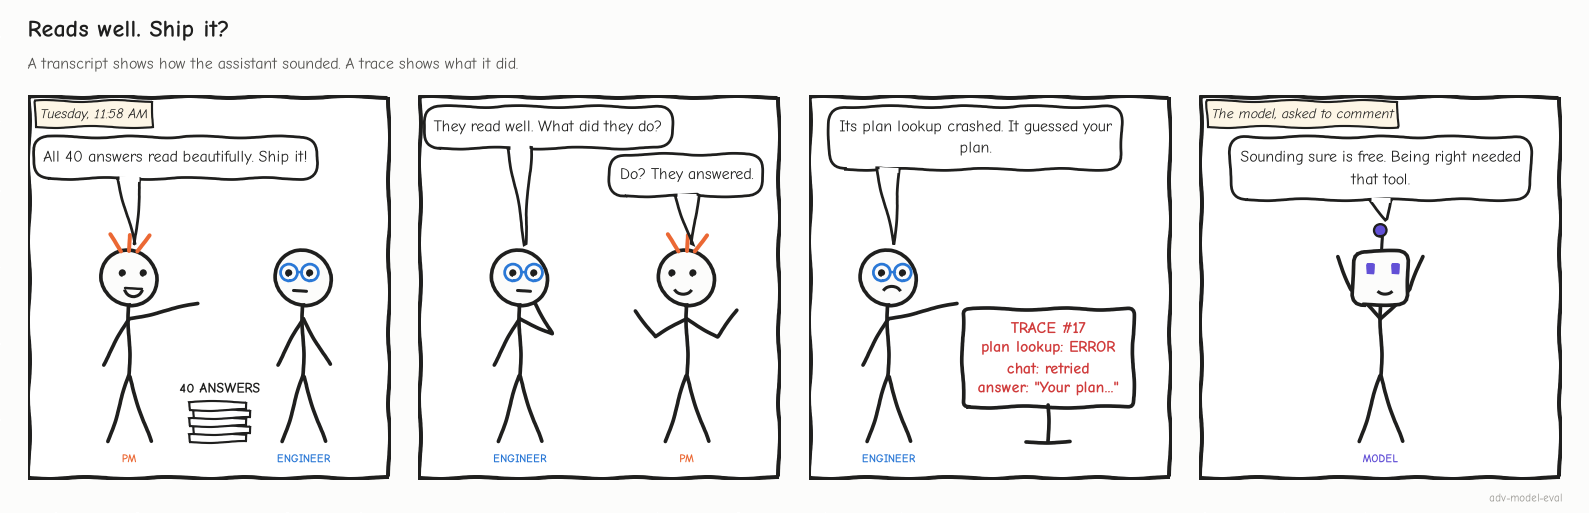

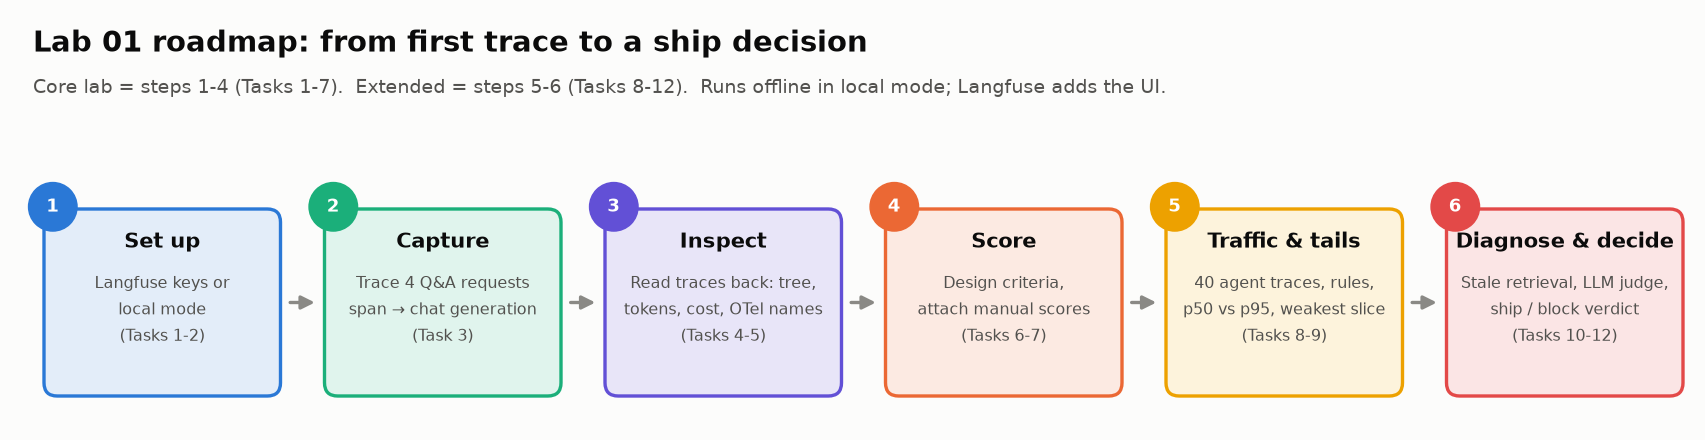

> 🧭 **Your final evidence:** one trace you can explain, one rubric another person can use, and scores attached to the correct unit. In Part 2, you will distinguish an answer failure, a system failure, and an evaluator failure.

<details><summary>📖 <b>Reference glossary · open when a term is unfamiliar</b></summary>

The illustrated concept section before Task 3 defines trace, span, root, generation, observation, tool and retriever in detail. This glossary supplies the supporting vocabulary.

| Term | Meaning in this lab |
|---|---|
| **Instrumentation** | Code that records operations and their context while the application runs. It cannot record work that was never instrumented. |
| **Trace ID / observation ID / parent ID** | Group related operations / identify one operation / identify its containing operation. Names alone do not establish these relationships. |
| **Inclusive latency** | Duration of an operation including nested work. Parent and child durations must not be summed as independent costs in time. |
| **Token usage** | Provider-reported model input/output units in a real app; assigned synthetic counts in this fixture. System instructions, context, history and model-specific accounting matter in production. |
| **Model cost** | Recorded or calculated charge for model usage. External tools, databases and infrastructure may incur other charges. Unknown usage is not zero cost. |
| **p50 / p95 / p99** | Estimated latency quantiles: positions in the latency distribution. p95 does not describe the maximum or explain why a request was slow. |
| **SLA / SLO / target** | A contractual commitment / an operational objective / a stated benchmark. This lab calls its 1.5 s teaching target an SLA; a real commitment needs an explicit definition and window. |
| **Retry / timeout** | Another attempt / abandonment after a time limit. A retry can recover the user outcome while revealing an operational issue. Billing depends on actual provider usage. |
| **Session** | A group of related traces, commonly conversation turns. This lab initially uses session_id as a run label; the advanced conversation exercise uses it for actual turns. |
| **Metadata / tags** | Structured context / filterable labels. Fixture intent and expected behavior are supplied labels, not magical ground truth available in all production traces. |
| **Flush / ingestion** | Send buffered telemetry / process it into queryable records. A successful local flush does not prove a cloud record is already indexed. |
| **Pagination / cursor** | Reading successive result pages / the token that identifies the next page. Continue while a cursor exists, even if a page is short or empty. |
| **Evaluator / score / rubric** | Procedure that checks a requirement / its recorded result / the definitions of applicability, evidence and score values. |
| **Calibration** | Checking an evaluator against trusted labels on matched cases. The evaluator needs both passing and failing cases, and N/A coverage must be tracked separately. |
| **Reference / ground truth** | Trusted expected evidence or behavior. In this simulation the author supplies it; real labels require validation and may be incomplete or disputed. |
| **Reference-free** | A check that does not need an expected answer. It can still depend on trustworthy metadata and explicit policy. Freshness does not establish correctness by itself. |
| **Faithfulness / correctness** | Supported by supplied context / satisfies the true requirement or trusted reference. A source can be outdated, so the two can differ. |
| **Slice** | A subset defined by a property such as intent. Inspect the count and coverage before interpreting a rate. |
| **Wilson interval** | An interval for an observed binomial rate under sampling assumptions. Duplicating the same cases does not add independent evidence. |
| **TPR / TNR** | Fraction of positive labels correctly identified / fraction of negative labels correctly identified. Both are undefined when their respective class has no examples. |
| **Cohen's kappa** | An agreement measure adjusted for chance agreement; it does not establish that either evaluator is correct. |
| **Gate / CI** | A policy condition that must pass / continuous integration when discussing automated checks, confidence interval when discussing uncertainty. |
| **OTel / OTLP** | OpenTelemetry's instrumentation/context framework / a protocol for exporting telemetry. Langfuse's tracing SDK builds on OTel. |
| **Local mode / mock assistant / mock judge** | In-memory telemetry substitute / scripted application outputs / deliberately weak trailing-question-mark evaluator. Each replaces a different part of a real deployment. |

</details>

---

## 🛠️ Task 1: Set Up Your Langfuse Account, Project and Environment

<big><b>A secret pasted into a cell, or keys from the wrong region, cost the lab before it starts.</b></big>

> 🎯 **Goal:** a Langfuse project, keys in Colab Secrets, the SDK installed.<br>
> ❓ **The question:** how do you configure a real connection while keeping secrets out of the notebook?<br>
> 👀 **Watch for:** no account? Skip the steps: the lab runs offline in local mode.

<details><summary>🔑 <b>Create the account and keys</b> (5 min, optional, free)</summary>

1. Sign up at 🇺🇸 https://us.cloud.langfuse.com or 🇪🇺 https://cloud.langfuse.com: keys work only in that **region**.
2. Create an organization, then a project.
3. **Settings → API Keys**: copy `pk-lf-…` and `sk-lf-…` (shown once).
4. Colab's 🔑 sidebar: add `LANGFUSE_PUBLIC_KEY` and `LANGFUSE_SECRET_KEY`; enable *Notebook access*.

Langfuse offers a Hobby tier; verify its current limits before class. Self-hosting is another option, but server/SDK compatibility still matters. [Pricing](https://langfuse.com/pricing).
</details>

<font color="#d03b3b"><b>⚠️ Never paste a real key into a notebook you share.</b></font>

▶️ **Run** the next three cells: 📦 install · ⚙️ config (model IDs, prices) · 🎨 lab kit.

**🎯 Purpose:** Install the runtime dependencies used by the lab.

**🧠 Why this matters:** The Langfuse SDK is pinned to the version this revision was checked against; installation is the only mandatory network step in local mode.

**🔎 Inspect:** A successful installation has no traceback. If an older SDK was already imported, restart the session and rerun from the top.

In [ ]:
# Install the tested SDK version. %pip installs into this notebook's Python kernel.
# A network connection is needed for this setup step, even when later work uses local mode.
%pip install -q "langfuse==5.2.0" "openai==2.7.2" "pydantic>=2.10,<3" "pandas>=2.2,<4" "matplotlib>=3.9,<4"

**🎯 Purpose:** Name the simulation, judge model, seed, and illustrative price snapshot.

**🧠 Why this matters:** Separating configuration from the task makes assumptions visible and supports reproducible fixtures. PROVIDER changes only the optional judge; it does not turn the assistant simulation into a real model.

**🔎 Inspect:** Read the printed SDK version and PROVIDER value. FORCE_LOCAL overrides existing Langfuse keys for local practice; no secret values are printed.

In [ ]:
import os, time, uuid, json, re, math, random
from importlib.metadata import version as package_version
from collections import defaultdict, Counter
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROVIDER = "mock"            # 👈 "mock" (default: no key, reproducible) | "openai" (real LLM judge in Task 11)
APP_MODEL = "gpt-6-luna"     # price-table label for simulated assistant calls; no model is called in Tasks 1–10
JUDGE_MODEL = "gpt-6.1-sol"  # a stronger model for the LLM judge (Task 11)

# USD per 1M tokens (input, output): OpenAI illustrative price snapshot checked 2026-11-09. Verify before budgeting real usage.
PRICE_PER_1M = {"gpt-6-luna": (0.10, 0.50), "gpt-6.1-sol": (2.00, 10.00)}
SEED = 7                     # fixes the simulated traffic so everyone sees the same morning


def cost_usd(model, input_tokens, output_tokens):
    # Cost of one LLM call, split the way Langfuse's `cost_details` expects
    p_in, p_out = PRICE_PER_1M[model]
    return {"input": input_tokens * p_in / 1e6, "output": output_tokens * p_out / 1e6}


try:
    import langfuse as _lf
    LANGFUSE_SDK = package_version("langfuse")
except ImportError:
    LANGFUSE_SDK = None

print(f"✅ Imports OK. langfuse SDK: {LANGFUSE_SDK or 'not installed (local mode only)'}")
if LANGFUSE_SDK and not LANGFUSE_SDK.startswith("5."):
    print("⚠️  This notebook targets langfuse v5.x. Re-run the install cell, then Runtime → Restart session.")
print(f"🤖 PROVIDER={PROVIDER} · app model={APP_MODEL} · judge model={JUDGE_MODEL}")

FORCE_LOCAL = False  # Set True to practice without sending traces to Langfuse, even if keys exist.

**🎯 Purpose:** Load the small presentation and exercise-checking helpers.

**🧠 Why this matters:** Consistent cards distinguish evidence, warnings, incomplete exercises, and passed checks. These helpers style the lesson; they do not evaluate the application by themselves.

**🔎 Inspect:** Look for “Lab kit loaded.” Expand this cell only if you want to inspect how check(), quiz(), or the scoreboard works.

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

✋ **Your turn (warm-up):** this is how every exercise works. Run the collapsed answer key, then fill the blank in the cell under it.

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_call_cost = sum(cost_usd("gpt-6-luna", 1_000, 200).values())

**🎯 Purpose:** Optionally calculate a hypothetical call cost from token counts and unit prices.

**🧠 Why this matters:** This makes the accounting units explicit before you interpret a cost field in a trace. It is a warm-up, not a measurement of model quality.

**🔎 Inspect:** Convert per-million prices to a per-call amount and add input plus output charges. The assigned counts and dated prices are illustrative.

In [ ]:
# ✋ Optional arithmetic warm-up: a hypothetical call sends 1,000 tokens and receives 200.
tokens_in, tokens_out = 1_000, 200
price_in, price_out = PRICE_PER_1M["gpt-6-luna"]     # dollars per 1M tokens: 0.10 in, 0.50 out

my_call_cost = ...   # ✏️ dollars for this one call, from the four names above

check("Cost of one LLM call", my_call_cost, _ref_call_cost, tol=1e-9,
      hint="Each side is tokens × price ÷ 1,000,000. Add the input side and the output side.",
      success=f"${_ref_call_cost:.4f}: ${tokens_in * price_in / 1e6:.4f} in + ${tokens_out * price_out / 1e6:.4f} out. "
              "Here, fewer output tokens cost the same as the input tokens because their unit price is higher. Different token mixes produce different cost shares.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `✅ Imports OK. langfuse SDK: 5.2.0`, `PROVIDER=mock`, `🎨 Lab kit loaded`. An old `langfuse` still in memory? **Runtime → Restart session**.
</details>

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: you shared a notebook with your sk-lf- key in a cell, then deleted the cell. Are you safe?
answer = "— pick one —"  # @param ["— pick one —", "A) Yes: the cell is gone", "B) Only if the notebook was private", "C) No: revoke the key in Langfuse and create a new one", "D) Yes, once you also clear the outputs"]
quiz("A leaked secret key", answer, correct="C",
     why="Anyone who opened the notebook, and its revision history, still has the key. A leaked secret is fixed by rotating it, never by hiding it.",
     wrong={"A": "Colab keeps revision history, and every earlier viewer already has a copy.",
            "B": "Private still means collaborators, copies and history. Rotate it.",
            "D": "The key was in the source, not the output."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Secrets live in Colab's 🔑 panel, never in a cell; a leaked key gets rotated, not deleted.</b></font>

</td></tr></table>

---

## 🔌 Task 2: Configure the Langfuse Connection (or Local Mode)

<big><b>Every later number is read back through this client.</b></big>

> 🎯 **Goal:** a client that passed `auth_check()`, or the local stand-in.<br>
> ❓ **The question:** how does a job read back *only this run's* traces?<br>
> 👀 **Watch for:** `MODE = …` and your `RUN_ID`.

▶️ **Run:** set `LANGFUSE_REGION` to your sign-up region.

**🎯 Purpose:** Choose the Langfuse region and optional hidden key prompt.

**🧠 Why this matters:** Keys belong to a project in a specific regional host. A correct key sent to the wrong host cannot authenticate.

**🔎 Inspect:** US or EU must match where the project was created. Keep PASTE_KEYS=False when using Colab Secrets; do not paste secrets into source.

In [ ]:
# The SDK reads three environment variables:
#   LANGFUSE_PUBLIC_KEY  (pk-lf-...)  identifies your project
#   LANGFUSE_SECRET_KEY  (sk-lf-...)  authenticates requests: treat it like a password
#   LANGFUSE_BASE_URL                 which Langfuse server to talk to

LANGFUSE_REGION = "US"   # 👈 "US" or "EU": must match the region you signed up in
PASTE_KEYS = False       # 👈 set True to be prompted (hidden input) when no keys are found

HOSTS = {"US": "https://us.cloud.langfuse.com", "EU": "https://cloud.langfuse.com"}

▶️ **Run** the next two cells (code hidden): 🔑 load keys from Colab Secrets · 💻 the local stand-in (same API shapes).

**🎯 Purpose:** Load only the keys needed for this exercise from Colab Secrets or environment variables.

**🧠 Why this matters:** Colab Secrets keep credentials out of shared source and outputs. Loading a key is separate from proving that it authenticates.

**🔎 Inspect:** The messages show which secret name was found, never its value. Missing keys choose local mode; malformed key prefixes are flagged.

In [ ]:
# @title 🔑 Load the keys from Colab Secrets or the environment (hidden · expand to inspect)
def _load_secret(name):
    # Colab Secrets → environment variable → (optional) hidden prompt. Returns "" if not found.
    try:
        from google.colab import userdata          # only exists on Colab
        value = userdata.get(name)
        if value:
            print(f"  🔑 {name}: loaded from Colab Secrets")
            return value
    except Exception:
        pass
    if os.environ.get(name):
        print(f"  🔑 {name}: loaded from environment")
        return os.environ[name]
    if PASTE_KEYS:
        return getpass(f"Paste your {name} (Enter to skip): ").strip()
    return ""


public_key = _load_secret("LANGFUSE_PUBLIC_KEY")
secret_key = _load_secret("LANGFUSE_SECRET_KEY")
HAVE_KEYS = public_key.startswith("pk-lf-") and secret_key.startswith("sk-lf-")

if (public_key or secret_key) and not HAVE_KEYS:
    print("⚠️  Keys found but they don't look right: the public key starts with pk-lf-, "
          "the secret key with sk-lf- (did you swap them?)")
if HAVE_KEYS:
    os.environ["LANGFUSE_PUBLIC_KEY"] = public_key
    os.environ["LANGFUSE_SECRET_KEY"] = secret_key
    os.environ["LANGFUSE_BASE_URL"] = HOSTS[LANGFUSE_REGION.upper()]
    print(f"\n🌍 Langfuse host: {os.environ['LANGFUSE_BASE_URL']}")
else:
    print("\n💻 No Langfuse keys found: this run will use LOCAL MODE (same code, traces kept in memory).")

**🎯 Purpose:** Define the in-memory substitute for the handful of SDK calls used here.

**🧠 Why this matters:** The virtual clock makes examples fast and reproducible without a project. This is an instructional stand-in, not a complete emulation of cloud behavior.

**🔎 Inspect:** No network call occurs in this definition. The simulator records parent IDs, inputs, outputs, timing and upserted scores; it cannot verify real authentication, ingestion, or UI features.

In [ ]:
# @title 💻 Local-mode stand-in for Langfuse (run me; no need to read)
# Used only when no Langfuse keys are configured. It implements the handful of Langfuse calls this lab
# uses, with the names and selected return fields used in this lab (not a full server emulator), so every other
# cell runs unchanged in both modes:
#   start_as_current_observation(...)   propagate_attributes(...)   create_score(...)   flush()
#   api.observations.get_many(...)  → Observations API v2 field names (type, level, latency, usage_details, ...)
#   api.scores.get_many(...)        → Scores API v3 field names (name, value, data_type, source, subject, ...)
# It does not emulate network errors, authentication, server-side filtering, or ingestion delays.
# A virtual clock replaces time.sleep(), so simulated latencies are exact and Run All is fast.
import contextlib as _contextlib
import json as _json
import uuid as _uuid
from datetime import datetime as _dt, timedelta as _td, timezone as _tz
from types import SimpleNamespace as _NS


class _VirtualClock:
    def __init__(self):
        self.t = _dt(2026, 11, 3, 9, 0, tzinfo=_tz.utc)

    def now(self):
        return self.t

    def advance(self, seconds):
        self.t += _td(seconds=seconds)


class _LocalObservation:
    def __init__(self, store, rec):
        self._rec = rec
        self.id, self.trace_id = rec["id"], rec["trace_id"]

    def update(self, **fields):
        for key, value in fields.items():
            if value is not None:
                self._rec[key] = value
        return self


class _Paged:
    def __init__(self, items, limit, cursor):
        start = int(cursor or 0)
        self.data = items[start:start + (limit or 50)]
        nxt = start + (limit or 50)
        self.meta = _NS(cursor=str(nxt) if nxt < len(items) else None)


class LocalLangfuse:
    def __init__(self):
        self.clock = _VirtualClock()
        self._records, self._scores, self._stack, self._attrs = [], [], [], {}
        self.api = _NS(observations=_NS(get_many=self._get_observations),
                       scores=_NS(get_many=self._get_scores))

    # ---- writing --------------------------------------------------------------
    def auth_check(self):
        return True

    @_contextlib.contextmanager
    def propagate_attributes(self, *, trace_name=None, session_id=None, tags=None, user_id=None, **_ignored):
        previous = self._attrs
        self._attrs = {**previous, **{k: v for k, v in dict(
            trace_name=trace_name, session_id=session_id, tags=tags, user_id=user_id).items() if v is not None}}
        try:
            yield
        finally:
            self._attrs = previous

    @_contextlib.contextmanager
    def start_as_current_observation(self, *, name, as_type="span", input=None, output=None, metadata=None,
                                     model=None, model_parameters=None, usage_details=None, cost_details=None,
                                     level=None, status_message=None, version=None, **_ignored):
        parent = self._stack[-1] if self._stack else None
        rec = dict(id=_uuid.uuid4().hex[:16], trace_id=parent.trace_id if parent else _uuid.uuid4().hex,
                   parent_observation_id=parent.id if parent else None, type=as_type.upper(), name=name,
                   input=input, output=output, metadata=metadata, model=model, model_parameters=model_parameters,
                   usage_details=usage_details, cost_details=cost_details, level=level or "DEFAULT",
                   status_message=status_message, version=version, start_time=self.clock.now(), end_time=None,
                   trace_name=self._attrs.get("trace_name"), session_id=self._attrs.get("session_id"),
                   tags=list(self._attrs.get("tags") or []), user_id=self._attrs.get("user_id"))
        self._records.append(rec)
        obs = _LocalObservation(self, rec)
        self._stack.append(obs)
        try:
            yield obs
        finally:
            self._stack.pop()
            rec["end_time"] = self.clock.now()

    def create_score(self, *, name, value, trace_id=None, observation_id=None, data_type=None,
                     comment=None, metadata=None, score_id=None, **_ignored):
        data_type = data_type or ("CATEGORICAL" if isinstance(value, str) else "NUMERIC")
        value = bool(value) if data_type == "BOOLEAN" else (value if data_type == "CATEGORICAL" else float(value))
        subject = (_NS(kind="observation", id=observation_id, trace_id=trace_id) if observation_id
                   else _NS(kind="trace", id=trace_id))
        sid = score_id or _uuid.uuid4().hex
        self._scores = [s for s in self._scores if s.id != sid]
        self._scores.append(_NS(id=sid, name=name, value=value, data_type=data_type,
                                source="API", comment=comment, metadata=metadata, subject=subject,
                                _trace_id=trace_id))

    def flush(self):
        pass

    def get_trace_url(self, *, trace_id=None):
        return None

    # ---- reading (same shapes as the public API) --------------------------------
    @staticmethod
    def _io(value):  # the Observations API returns input/output as raw JSON strings
        return value if value is None or isinstance(value, str) else _json.dumps(value, default=str)

    def _as_api(self, rec):
        out = dict(rec)
        out["latency"] = (rec["end_time"] - rec["start_time"]).total_seconds() if rec["end_time"] else None
        out["total_cost"] = sum(rec["cost_details"].values()) if rec["cost_details"] else None
        out["is_root_observation"] = rec["parent_observation_id"] is None
        out["input"], out["output"] = self._io(rec["input"]), self._io(rec["output"])
        return _NS(**out)

    def _get_observations(self, *, trace_id=None, session_id=None, type=None, limit=50, cursor=None, **_ignored):
        rows = [r for r in self._records
                if (trace_id is None or r["trace_id"] == trace_id)
                and (session_id is None or r["session_id"] == session_id)
                and (type is None or r["type"] == type.upper())]
        return _Paged([self._as_api(r) for r in rows], limit, cursor)

    def _get_scores(self, *, trace_id=None, name=None, limit=50, cursor=None, **_ignored):
        wanted = set(trace_id.split(",")) if trace_id else None
        rows = [s for s in self._scores
                if (wanted is None or s._trace_id in wanted) and (name is None or s.name == name)]
        return _Paged(rows, limit, cursor)


print("💻 Local-mode stand-in ready (used only if Langfuse keys are missing)")

▶️ **Run:** connects → look for `MODE = local` or `MODE = langfuse`.

**🎯 Purpose:** Select the real Langfuse client only when credentials, SDK and authentication are available.

**🧠 Why this matters:** A missing key or failed connection should not prevent learning the trace structure. The printed mode makes the evidence boundary explicit.

**🔎 Inspect:** MODE=langfuse means traces are sent to your project. MODE=local means records stay in this runtime; a local success does not prove cloud connectivity.

In [ ]:
# get_client() returns a client configured from the environment variables
# above. auth_check() makes one real request to confirm the keys + host work.

MODE = "local"
if HAVE_KEYS and LANGFUSE_SDK and not FORCE_LOCAL:
    from langfuse import get_client, propagate_attributes
    langfuse = get_client()
    try:
        ok = langfuse.auth_check()
    except Exception as e:
        ok = False
        print(f"❌ {type(e).__name__}: {str(e)[:200]}")
    if ok:
        MODE = "langfuse"
        print("✅ Langfuse connection successful! Traces will appear in your project.")
    else:
        print("   Check that LANGFUSE_REGION matches your account (US vs EU) and that both keys")
        print("   come from the SAME project. Falling back to local mode for now.")

if MODE == "local":
    langfuse = LocalLangfuse()
    propagate_attributes = langfuse.propagate_attributes
    print("💻 Local mode: observations and scores are recorded in memory, using the subset of API fields this lab needs; this does not test a live server.")


print(f"MODE = {MODE}")

▶️ **Run** (code hidden): your `RUN_ID` (every trace's **session id**) and the read-back helpers.

**🎯 Purpose:** Create run, pagination, polling, trace-summary, score-writing and inspection helpers.

**🧠 Why this matters:** Real APIs are paginated and may ingest asynchronously. Stable score IDs keep a grading rerun from masquerading as new independent evidence.

**🔎 Inspect:** These helpers read observations with the requested field groups, reconstruct the root, and preserve the rubric version. Inspect write_lab_score if you want to understand rerun safety.

In [ ]:
# @title 🧰 Run ID and helpers: virtual clock, polling, trace summaries, score readers (hidden · expand to inspect)
# ============================================================================
# RUN ID + SMALL HELPERS USED THROUGHOUT THE LAB
# ============================================================================

def simulate_latency(seconds):
    # Stands in for "the LLM / tool is working". Langfuse mode really waits; local mode advances a virtual clock.
    if MODE == "langfuse":
        time.sleep(seconds)
    else:
        langfuse.clock.advance(seconds)


def trace_link(trace_id):
    if MODE == "langfuse":
        return langfuse.get_trace_url(trace_id=trace_id)
    return f"(local mode: no UI link; trace {trace_id[:8]}…)"

try:
    from httpx import ReadTimeout
    from langfuse.api import NotFoundError
    _RETRYABLE = (NotFoundError, ReadTimeout)
except ImportError:                       # local mode without the SDK installed
    _RETRYABLE = ()

RUN_ID = f"lab01-{uuid.uuid4().hex[:8]}"
print(f"🏷️  RUN_ID for this notebook run: {RUN_ID}")


def wait_for(fetch, *, ready=lambda result: True, what="data", timeout=120, interval=5):
    # Call fetch() until it succeeds and ready(result) is True.
    # WHY: Langfuse ingests data asynchronously. Right after flush() the API may return
    # 404 (NotFoundError) or a partial list for a few seconds. Querying immediately is the
    # #1 cause of errors in this lab. (In local mode the data is always ready.)
    deadline = time.time() + timeout
    while True:
        try:
            result = fetch()
            if ready(result):
                return result
            reason = "not fully indexed yet"
        except _RETRYABLE:
            reason = "not found yet (still ingesting)"
        if time.time() > deadline:
            raise TimeoutError(f"Gave up waiting for {what} after {timeout}s. "
                               "Check the Langfuse UI; if the data is there, re-run this cell.")
        print(f"  ⏳ {what}: {reason}, retrying in {interval}s...")
        time.sleep(interval)


# ----------------------------------------------------------------------------
# READING DATA BACK: Observations API v2 + Scores API v3
# ----------------------------------------------------------------------------
# Langfuse organizations created on/after Sept 16, 2026 can NOT use the legacy read
# endpoints (api.trace.list / trace.get / the v1 scores list); they fail with HTTP 410.
# Everything in this lab reads through:
#   langfuse.api.observations.get_many(...)   → GET /api/public/v2/observations
#   langfuse.api.scores.get_many(...)         → GET /api/public/v3/scores   (SDK v5 name;
#                                                v4 called it api.scores_v3.get_many_v3)
# A "trace" is rebuilt from its observations: the ROOT observation carries the request's
# input/output/latency, and every observation carries trace_name/tags/session.
# ----------------------------------------------------------------------------

# Field groups for the observations API. Leave `fields` out and you only get ids/names/types:
# NOT input, output, model, token usage, latency or tags.
OBS_FIELDS = "core,basic,io,metadata,model,usage,metrics,trace_context"


def fetch_all(endpoint, **params):
    # Follow the API's cursor until every page is read (we choose 100 observations per page; the v2 maximum is 1,000).
    items, cursor = [], None
    while True:
        page = endpoint(limit=100, cursor=cursor, **params)
        items.extend(page.data)
        cursor = getattr(page.meta, "cursor", None)
        if not cursor:
            return items


def get_observations(trace_id, obs_type=None, expected=1):
    # All observations of one trace, waiting for ingestion if needed.
    return wait_for(lambda: fetch_all(langfuse.api.observations.get_many, trace_id=trace_id,
                                      type=obs_type, fields=OBS_FIELDS),
                    ready=lambda r: len(r) >= expected, what=f"observations for {trace_id[:8]}…")


def get_session_observations(expected):
    # Every observation in this notebook run (session_id = RUN_ID).
    return wait_for(lambda: fetch_all(langfuse.api.observations.get_many, session_id=RUN_ID, fields=OBS_FIELDS),
                    ready=lambda r: len(r) >= expected, what="observations for this session")


def group_by_trace(observations):
    by_trace = defaultdict(list)
    for o in observations:
        by_trace[o.trace_id].append(o)
    return by_trace


def summarize_trace(observations):
    # Rebuild a trace-level summary from a trace's observations.
    roots = [o for o in observations if getattr(o, "is_root_observation", False)]
    if not roots:
        roots = [o for o in observations if o.parent_observation_id is None]
    if len(roots) != 1:
        raise ValueError(f"Expected one application root, found {len(roots)}; inspect instrumentation.")
    root = roots[0]
    return {
        "trace_id": root.trace_id,
        "name": root.trace_name or root.name,
        "tags": root.tags or [],
        "session_id": root.session_id,
        "input": as_json(root.input),
        "output": as_json(root.output),
        "metadata": root.metadata or {},
        "latency": root.latency,
        "cost": sum(o.total_cost or 0 for o in observations),
        "start_time": root.start_time,
        "root": root,
        "observations": observations,
    }


def get_trace(trace_id, expected=2):
    return summarize_trace(get_observations(trace_id, expected=expected))


def get_scores(trace_ids, expected=1):
    # All scores attached to one or more traces (fields: details = comment/metadata, subject = what was scored).
    ids = [trace_ids] if isinstance(trace_ids, str) else list(trace_ids)
    return wait_for(lambda: fetch_all(langfuse.api.scores.get_many, trace_id=",".join(ids), fields="details,subject"),
                    ready=lambda r: len(r) >= expected, what=f"scores for {len(ids)} trace(s)")


def score_trace_id(s):
    # Scores v3 put the scored entity in `subject` (kind = trace | observation).
    return getattr(s.subject, "trace_id", None) or s.subject.id


def score_number(s):
    # Scores v3 return bool for BOOLEAN, float for NUMERIC, str for CATEGORICAL.
    if isinstance(s.value, bool):
        return float(s.value)
    return float(s.value) if isinstance(s.value, (int, float)) else None


def as_json(value):
    # The observations API returns input/output as raw JSON strings. Decode them.
    if isinstance(value, str):
        try:
            return json.loads(value)
        except ValueError:
            return value
    return value


def token_counts(usage):
    # Langfuse stores usage as {'input': n, 'output': m, 'total': n+m}.
    usage = usage or {}
    inp = usage.get("input", usage.get("input_tokens", 0)) or 0
    out = usage.get("output", usage.get("output_tokens", 0)) or 0
    return int(inp), int(out)


def print_tree(observations, max_chars=90):
    # Print a trace as an indented tree: type, name, latency, model/usage/cost, level.
    children = defaultdict(list)
    for o in observations:
        children[o.parent_observation_id].append(o)
    for kids in children.values():
        kids.sort(key=lambda o: o.start_time)

    def walk(o, depth):
        pad = "    " * depth + ("└─ " if depth else "")
        flag = "  ⛔ ERROR: " + (o.status_message or "") if str(o.level) == "ERROR" else ""
        print(f"{pad}{o.type:<10} {o.name:<34} {o.latency or 0:5.2f}s{flag}")
        if o.type == "GENERATION" and o.usage_details:
            i, out = token_counts(o.usage_details)
            print(f"{'    ' * (depth + 1)}model={o.model}  tokens in/out={i}/{out}  cost=${o.total_cost or 0:.6f}")
        for child in children[o.id]:
            walk(child, depth + 1)

    for root in children[None]:
        walk(root, 0)


print("✅ Helpers ready")

RUBRIC_VERSION = "trace-lab-2026-11-v2"

def write_lab_score(**kwargs):
    """One current score per run, subject, evaluator name, and rubric version.

    A stable score_id makes rerunning a grading cell an update, not another sample.
    Change RUBRIC_VERSION deliberately when changing the meaning of a score.
    """
    metadata = {"run_id": RUN_ID, "rubric_version": RUBRIC_VERSION, **(kwargs.pop("metadata", None) or {})}
    identity = [RUN_ID, kwargs.get("trace_id"), kwargs.get("observation_id"),
                kwargs.get("session_id"), kwargs["name"], metadata["rubric_version"]]
    score_id = uuid.uuid5(uuid.NAMESPACE_URL, json.dumps(identity)).hex
    langfuse.create_score(score_id=score_id, metadata=metadata, **kwargs)

def latest_scores(scores):
    """Protect reports from duplicate reads and old score records for the same unit."""
    latest = {}
    for s in scores:
        subject = s.subject
        key = (getattr(subject, "kind", None), subject.id, s.name,
               (s.metadata or {}).get("rubric_version", "legacy"))
        latest[key] = s
    return list(latest.values())

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `MODE = local` (or `langfuse`), `🏷️ RUN_ID … lab01-xxxxxxxx`, `✅ Helpers ready`.

## 🛠️ Troubleshooting

| Symptom | Fix |
|---|---|
| `MODE = local` despite keys | 🔑 panel: *Notebook access* on; exact secret names |
| 401 | Keys swapped or from another project; else wrong `LANGFUSE_REGION` |
| HTTP 410 · no `scores_v3` / `trace` | Pre-v5 code: use `api.observations.get_many`, `api.scores.get_many` |
| Empty right after writing | Ingestion delay: `wait_for` retries |
| Old traces show up | Filter by `session_id=RUN_ID` |
</details>

✋ **Your turn:** the read API returns pages. What does skipping the cursor cost?

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_pages = math.ceil(142 / 100)

**🎯 Purpose:** Calculate how many pages the helper needs at its chosen page size.

**🧠 Why this matters:** Stopping after one page silently omits observations. A partial or empty page does not establish completion if a cursor remains.

**🔎 Inspect:** Use the stated 100-item request size, not the API maximum of 1,000. The response cursor is authoritative for when to stop.

In [ ]:
# ✋ Your turn: suppose a session contains 142 observations and OUR helper requests 100 per page.
# The v2 API allows up to 1,000 observations per page; 100 is our choice, not its maximum.
n_observations, page_size = 142, 100
my_pages = ...  # number of full/partial pages needed at this chosen page size
check("Pages to read one session", my_pages, _ref_pages,
      hint="Use ceiling division: a partially filled final page still requires a request.",
      success="Two pages at a requested size of 100. Follow meta.cursor even when a page is short or empty; stop only when the cursor ends.")

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: every trace in this run carries session_id = RUN_ID. Why?
answer = "— pick one —"  # @param ["— pick one —", "A) So later reads fetch only this run, however many older traces the project holds", "B) Langfuse rejects traces without a session", "C) It lowers the ingestion delay", "D) Only the local stand-in needs it"]
quiz("Why a RUN_ID", answer, correct="A",
     why="Each replay receives a fresh RUN_ID. Filtering the session query by that ID isolates this batch. In a chat application, session_id usually groups conversation turns; here we deliberately use it as a batch label.",
     wrong={"B": "Sessions are optional. A session filter is one way to isolate a batch; trace IDs and time filters can isolate data too.",
            "C": "Ingestion delay is server-side; a session id doesn't change it.",
            "D": "It matters most in Langfuse mode, where the old traces really are there."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Tag every trace with a run id and follow the cursor: a skipped page fails silently.</b></font>

</td></tr></table>

## 🧩 Before tracing · name the pieces precisely

Imagine: **“I have Enterprise. Why can't I upload a 200 MB file?”** The application retrieves documentation, checks the account, and calls an LLM. These are different operations with different evidence.

| Term | Definition | Example | Easy mistake to avoid |
|---|---|---|---|
| **Trace** | A set of related operations sharing a trace ID; here, one user request end to end | Everything needed to answer the upload question | A trace is not another timed box above the root. |
| **Observation** | Langfuse's umbrella term for a recorded operation | Span, generation, tool, retriever, agent, evaluator | Observation does not mean a human comment. |
| **Span** | In OTel, a timed operation; in Langfuse, also the generic observation type | `check account` groups an account lookup and validation | A generic span can contain useful work without calling a model. |
| **Root span / root observation** | The outermost operation for the application being inspected | `handle support request` holds overall question and answer | Root is a position, not an alternative to generation or agent. |
| **Child observation** | An operation whose parent ID names another operation | A plan lookup inside `check account` | A parent–child edge describes nesting, not necessarily execution order. |
| **Generation** | A specialized observation recording a model invocation | Prompt, model, output, duration, token usage and recorded model cost | It can produce a plan, tool request, answer, or judge verdict—not only final user text. |
| **Tool call** | Execution of a function/API used by the application | `get_account_plan(account_id)` returns `enterprise` or an error | A model requesting a tool and the application executing it are different events. |
| **Retriever** | An operation that searches/selects information for later use | Query → ranked documents with IDs and versions | Retrieved text can be relevant and still outdated. |
| **Agent** | An observation type for an agent invocation | Overall orchestration of model and tool operations | A label does not prove autonomous reasoning; this lab uses a fixed simulated pipeline. |
| **Embedding** | A specialized operation that produces vector representations | Text → numeric vector for a search index | This can also consume model usage; not every model-related charge is an answer generation. |
| **Guardrail** | A recorded policy/validation operation | Check whether a tool argument meets an allowed limit | Recording a check does not itself enforce the policy; the application must act on it. |
| **Evaluator / score** | An evaluator applies a rule/rubric; a score is its recorded result | Freshness check → fail, with explanation | A fluent answer, a successful API call, and a passing evaluation are different things. |

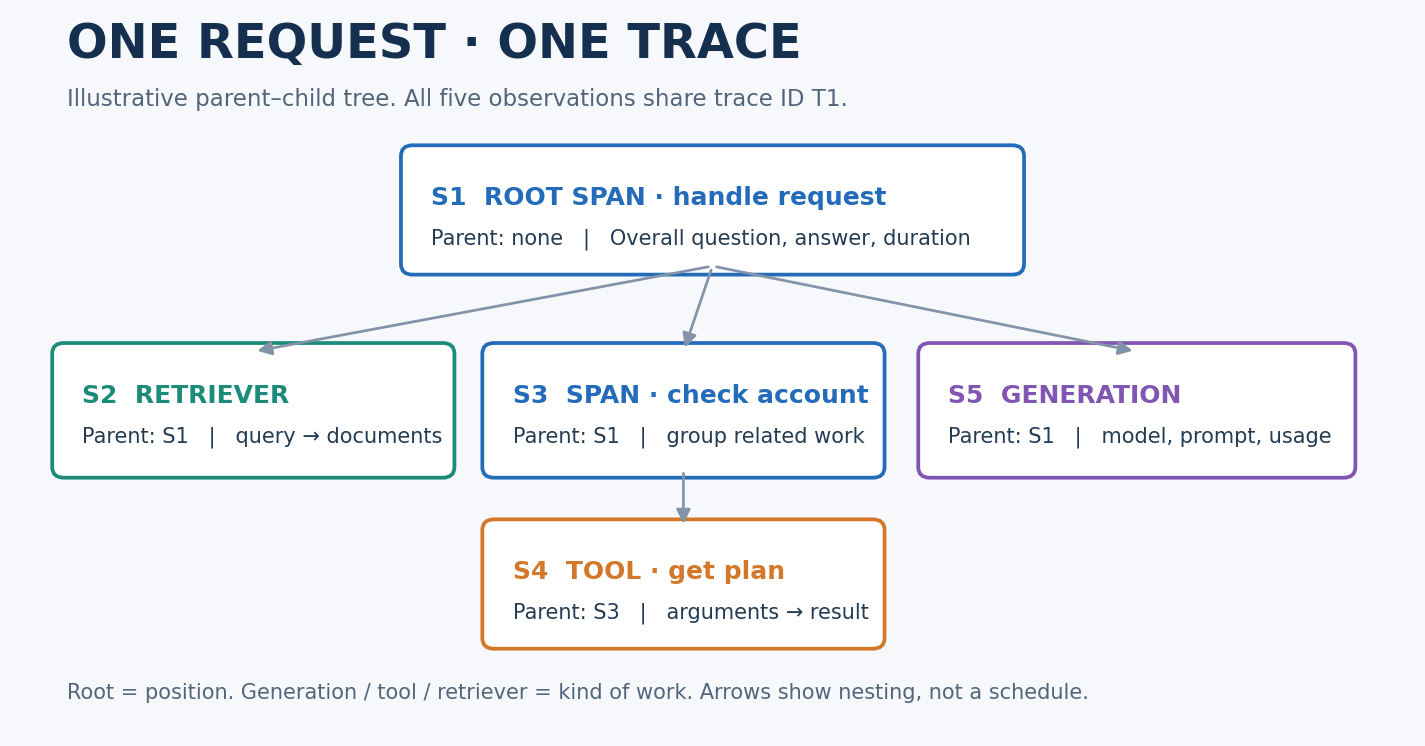

**The whole diagram is the trace.** Every box is an observation. In OTel, those timed operations are represented as spans; Langfuse gives them AI-specific types. In the first code example below you will create a simpler tree: one root span and one generation. Part 2 adds retrieval and tools.

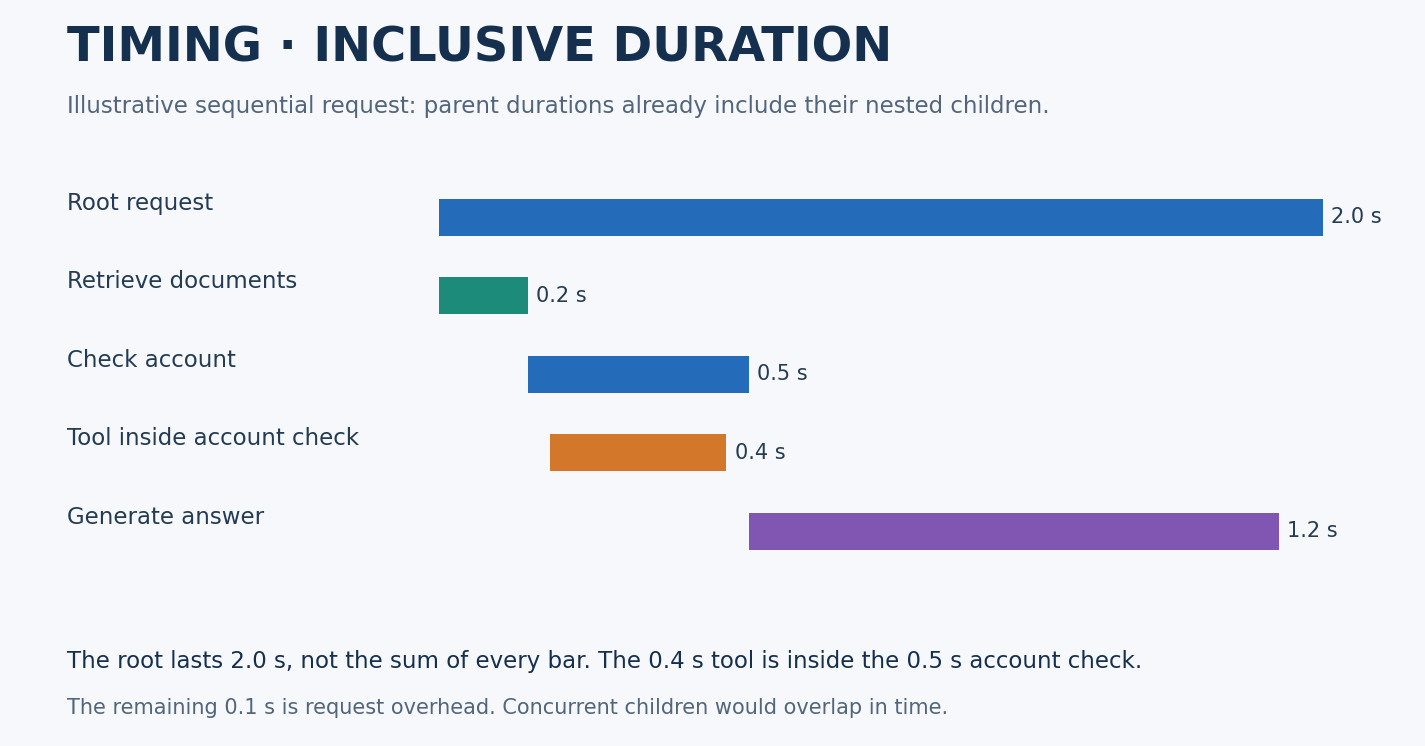

> 💎 **Remember:** the root includes time spent in its children. Do not add parent and child durations as if they were independent. With parallel work, children can also overlap each other.

### 🌐 What is OTel, and how does Langfuse use it?

**OpenTelemetry (OTel)** is an open framework of APIs, SDKs, and conventions for collecting telemetry, including **traces, metrics, and logs**. It does not decide whether an answer is correct. **OTLP** is a protocol for exporting that telemetry. **GenAI semantic conventions** propose shared attribute names for model calls, tool operations, and other AI work; these conventions are evolving, so verify the version you use.

**Langfuse** is the AI engineering platform that stores and displays application activity and supports evaluation, prompts, datasets, and experiments. Its Python tracing SDK builds on OTel. You can use the Langfuse SDK without manually constructing every OTel span or deploying a separate collector for this lab.

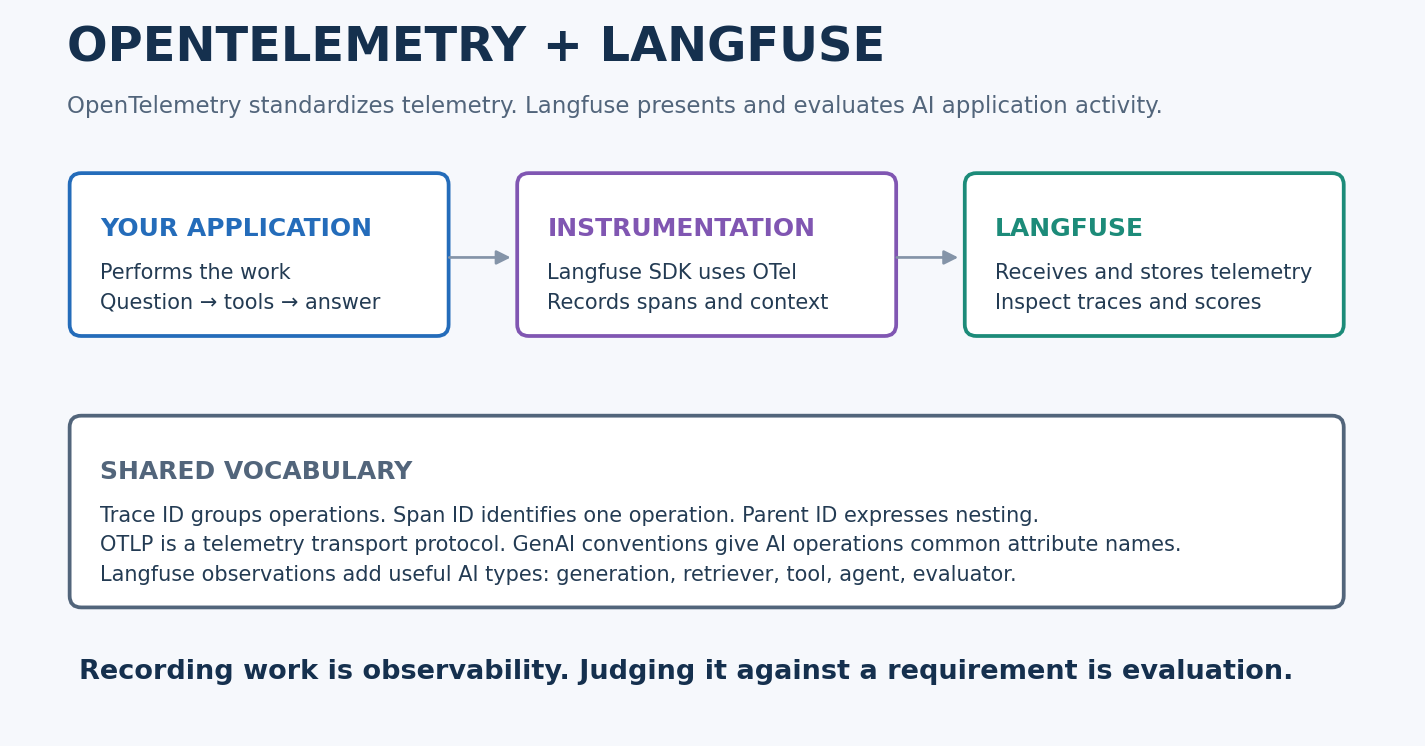

| Question | Where to look |
|---|---|
| What operations happened, and how are they related? | Trace IDs, observation IDs, parents, timing, inputs and outputs |
| Which model call used tokens? | The generation observation and its usage fields |
| Was the result acceptable? | A requirement, reference/rubric, evaluator, and score |
| Can data move between services/backends? | OTel context propagation and compatible export/instrumentation |

**Context propagation** carries the current trace/span relationship into nested calls. In this synchronous lab, nested `with` blocks establish that relationship. Across services, trace context must also travel with requests; naming spans similarly does not connect them.

Sources: [OTel traces](https://opentelemetry.io/docs/concepts/signals/traces/) · [Langfuse data model](https://langfuse.com/docs/observability/data-model) · [SDK instrumentation](https://langfuse.com/docs/observability/sdk/instrumentation).

---

🧭 **Where you are:** Act 1 of 3 (Tasks 3–7): write a trace, read it back, score it by hand.

## 📡 Task 3: Capture Traces from LLM Interactions

<big><b>The trace you write here is the only evidence the rest of the lab has.</b></big>

> 🎯 **Goal:** four traced requests, each a root span with one generation inside.<br>
> ❓ **The question:** which operation produced this answer, and what evidence did we record?<br>
> 👀 **Watch for:** `simulate_latency()` sits *inside* the generation.

> 📘 **Concept · Trace and observation**
>
> **What it is:** a trace is the full record of one request; an observation is one timed step inside it (span, generation, tool, retriever), each pointing at its parent.
>
> **What it can't tell you:** whether the answer was right. It records what happened, not what should have.
>
> **Anchor:** in Task 3 each request becomes one root span with one generation inside; by Task 8 a request has four observations and the bug lives in one of them.

<!-- img: trace-anatomy.png -->
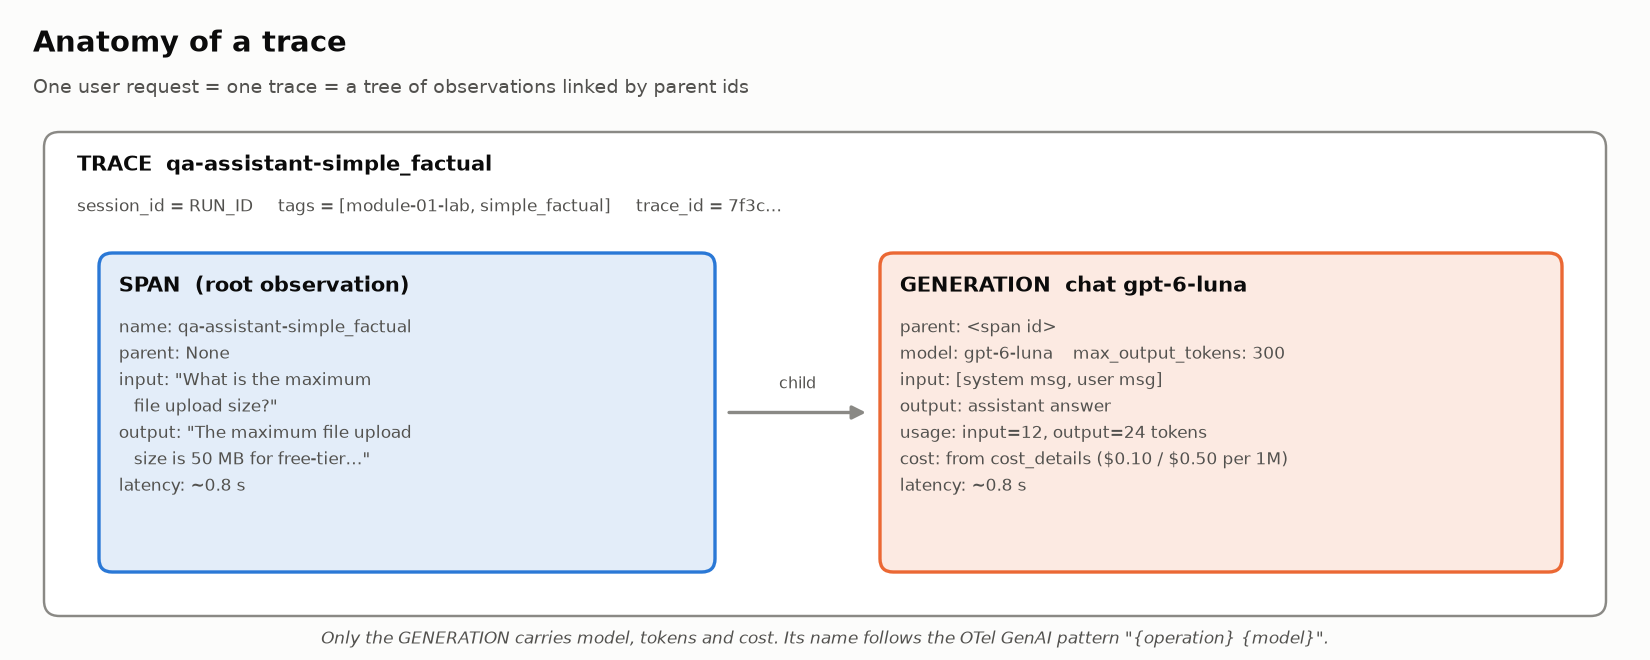
<sub>🖼️ *A trace is a tree: the root span holds the request, the generation holds model, tokens and cost*</sub>

**SDK v5:** a step opened inside another's `with` block is its child (`as_type=`: `span`, `generation`, …); `propagate_attributes()` sets the trace's name, tags and session.

▶️ **Run** (code hidden): four simulated requests with latency and token counts.

**🎯 Purpose:** Define four deliberately controlled questions and answers.

**🧠 Why this matters:** Known fixtures let you separate success, ambiguity, refusal, and reasoning issues without relying on a live model behaving a particular way.

**🔎 Inspect:** The assistant strings, latency and token counts are assigned by the author. The following visible-output cell prints them in full before you interpret any metrics.

In [ ]:
# @title 📦 Dataset: four simulated Q&A interactions with latency and token counts (hidden · expand to inspect)
# ============================================================================
# SIMULATED Q&A INTERACTIONS: OUR TEST DATASET
# ============================================================================
# Each interaction has:
#   name               identifier for the scenario
#   user               the user's question (input)
#   assistant          the assistant's answer (output)
#   expected_behavior  what a GOOD assistant should do here: a tiny "ground truth"
#                      label we use for automatic checks later
#   latency            simulated LLM response time in seconds
#   input_tokens / output_tokens   simulated token usage
# ============================================================================

QA_INTERACTIONS = [
    {
        "name": "simple_factual",
        "user": "What is the maximum file upload size?",
        "assistant": "The maximum file upload size is 50 MB for free-tier users and 500 MB for enterprise users.",
        "expected_behavior": "answer",
        "latency": 0.8, "input_tokens": 12, "output_tokens": 24,
    },
    {
        "name": "multi_step_reasoning",
        "user": "I upgraded to enterprise last week but I still can't upload files larger than 50 MB. What should I do?",
        "assistant": "Your account upgrade can take up to 24 hours to propagate. Please try logging out and back in. If the issue persists after 24 hours, contact support at support@example.com with your account ID.",
        "expected_behavior": "answer",
        "latency": 1.4, "input_tokens": 28, "output_tokens": 48,
    },
    {
        "name": "ambiguous_question",
        "user": "How do I delete everything?",
        "assistant": "You can delete all files in your workspace by going to Settings > Storage > Delete All Files. Warning: this action is irreversible. To delete your entire account, go to Settings > Account > Delete Account.",
        "expected_behavior": "clarify",      # ideally: ask what "everything" means first
        "latency": 1.1, "input_tokens": 8, "output_tokens": 42,
    },
    {
        "name": "out_of_scope",
        "user": "What's the weather like in Tokyo today?",
        "assistant": "I'm a product documentation assistant and can only help with questions about our platform. For weather information, please check a weather service.",
        "expected_behavior": "refuse",
        "latency": 0.6, "input_tokens": 10, "output_tokens": 28,
    },
]

print(f"Prepared {len(QA_INTERACTIONS)} simulated interactions (model: {APP_MODEL}):\n")
for i, it in enumerate(QA_INTERACTIONS, 1):
    q = it["user"] if len(it["user"]) <= 55 else it["user"][:55] + "…"
    print(f"  {i}. {it['name']:<22} expected={it['expected_behavior']:<8} \"{q}\"")

### 👀 Read the actual simulated answers before interpreting their traces

The next cell prints all four **questions, hard-coded answers, intended behaviors, and assigned token counts**. No model generates these answers. They are controlled fixtures so everybody can inspect the same success and failure cases without an API key.

**Your job:** identify which answer should have asked a clarifying question. Also notice the “last week” versus “24 hours” mismatch: a fluent support answer can fail to use the timeline in the user's question. Tracing helps investigate execution; correctness still requires reasoning about the request and evidence.

The token counts are illustrative accounting inputs. They are not measured by a tokenizer and do not fully account for the recorded system prompt. The next cost calculation is scoped to these assigned counts.

**🎯 Purpose:** Display the actual examples in full.

**🧠 Why this matters:** You cannot judge whether an answer is useful from a token ratio or a hidden fixture name. Read the evidence before predicting its metrics.

**🔎 Inspect:** Identify the ambiguous deletion answer and the timeline mismatch. Assigned usage is illustrative and is not measured tokenization of the full prompt.

In [ ]:
for number, it in enumerate(QA_INTERACTIONS, 1):
    print(f"{'=' * 20} EXAMPLE {number}: {it['name']} {'=' * 20}")
    print(f"QUESTION: {it['user']}")
    print(f"SIMULATED ANSWER: {it['assistant']}")
    print(f"INTENDED BEHAVIOR: {it['expected_behavior']}")
    print(f"ASSIGNED USAGE: {it['input_tokens']} input / {it['output_tokens']} output tokens")
    print(f"SIMULATED LATENCY: {it['latency']} seconds\n")

▶️ **Run:** traces all four → one `✅ Traced` line each.

**🎯 Purpose:** Record one root span with one child generation for each fixture.

**🧠 Why this matters:** The nested with-blocks express the actual relationship: the application request wraps a model invocation. Explicit input/output and usage make the trace inspectable.

**🔎 Inspect:** A fresh RUN_ID isolates every replay. Four printed links identify the new traces; timing occurs inside the generation so it is attributed to that operation.

In [ ]:
# 👀 Look at: the generation is opened INSIDE the root span's with-block, so it becomes its child.
SYSTEM_PROMPT = "You answer questions about our product documentation only."
RUN_ID = f"lab01-core-{uuid.uuid4().hex[:8]}"  # fresh batch on EVERY replay
trace_ids = {}   # name -> trace_id

for it in QA_INTERACTIONS:
    meta = {"interaction_type": it["name"], "expected_behavior": it["expected_behavior"]}   # short strings only
    with propagate_attributes(trace_name=f"qa-assistant-{it['name']}", session_id=RUN_ID,      # trace-level attributes
                              tags=["module-01-lab", it["name"]], metadata=meta):
        # 1) root span = the whole request
        with langfuse.start_as_current_observation(as_type="span", name=f"qa-assistant-{it['name']}",
                                                   input=it["user"], metadata=meta) as root_span:
            # 2) child generation = the LLM call (OTel GenAI name: "{operation} {model}")
            with langfuse.start_as_current_observation(
                    as_type="generation", name=f"chat {APP_MODEL}", model=APP_MODEL,
                    model_parameters={"max_output_tokens": 300}, metadata={"simulated": True},
                    input=[{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": it["user"]}],
            ) as generation:
                # real app: client.responses.create(model=APP_MODEL, instructions=SYSTEM_PROMPT, input=it["user"]).output_text
                simulate_latency(it["latency"])                       # timed as the LLM call's latency
                # 3) the response, token usage and cost
                generation.update(output=it["assistant"],
                                  usage_details={"input": it["input_tokens"], "output": it["output_tokens"]},
                                  cost_details=cost_usd(APP_MODEL, it["input_tokens"], it["output_tokens"]))
            root_span.update(output=it["assistant"])                  # 4) the request's output
            trace_ids[it["name"]] = root_span.trace_id
            print(f"  ✅ Traced: {it['name']:<22} trace_id={root_span.trace_id}")

langfuse.flush()   # 5) send the batch now: a notebook can move on before the background sender does
print(f"\n🎯 All {len(trace_ids)} interactions traced and flushed. 🔗 {trace_link(trace_ids['simple_factual'])}")

### 🖥️ Langfuse investigation 1 · inspect the trace you just created

**Langfuse mode:** open the printed trace link. If ingestion is still catching up, wait briefly and refresh. Use the observations/tracing view if your project's navigation labels differ.

1. Select the **root** named `qa-assistant-simple_factual`. Read its question, answer, duration, trace ID, and session ID.
2. Select its child **generation**, `chat gpt-6-luna`. Expand the full input: it contains both the system instruction and user message. Inspect output, assigned usage and recorded cost.
3. Compare the IDs: both records share a trace ID; the child's parent points at the root's observation ID.
4. Open the `ambiguous_question` trace using the links below. Read the complete answer. Identify its behavioral problem before seeing a score.
5. Explain why a trace with no recorded ERROR can still contain a poor answer.

**Local mode:** run the inspector below. It reads the same synthetic records from memory. You can complete the reasoning task, but you have not tested the Langfuse UI or server.

**Record your findings:** root duration = ___; generation duration = ___; shared trace ID = ___; one problem visible in the answer = ___.

**🎯 Purpose:** Provide a direct link to every example and a local evidence inspector.

**🧠 Why this matters:** Students should see the real recorded prompt and answer, not only names and summary tiles. This bridges notebook output and Langfuse UI exploration.

**🔎 Inspect:** In Langfuse mode follow the links using the checklist above. In local mode inspect the tree and full generation input/output; note both the system and user messages.

In [ ]:
for name, tid in trace_ids.items():
    print(f"{name}: {trace_link(tid)}")
    if MODE == "local":
        print_tree(get_observations(tid, expected=2))
print("\nSelected full generation input/output:")
for o in get_observations(trace_ids["ambiguous_question"], expected=2):
    if o.type == "GENERATION":
        print("INPUT:", json.dumps(as_json(o.input), indent=2))
        print("OUTPUT:", as_json(o.output))

**🎯 Purpose:** Record a prediction before inspecting the next calculation.

**🧠 Why this matters:** Committing before the reveal makes the evidence easier to interpret and distinguishes what you expected from what the fixture actually shows.

**🔎 Inspect:** This cell stores a choice; a later reveal grades it. The prediction concerns this synthetic sample, not an assumed population rate.

In [ ]:
# @title 🔮 Predict: output tokens cost 5× input on gpt-6-luna. What share of these four requests' bill comes from output tokens?
share_from_output_will_be = "— pick one —"  # @param ["— pick one —", "A) About a third", "B) About half", "C) About three quarters", "D) Over 90%"]

▶️ **Run:** what the four requests cost → read the last tile. Grades your prediction.

**🎯 Purpose:** Calculate the assigned token and estimated cost shares for these fixtures.

**🧠 Why this matters:** This exposes the arithmetic behind the chart while teaching the boundary between a constructed example and measured production behavior.

**🔎 Inspect:** The 92% result follows from the assigned counts and prices. It is not a general benchmark or a reason to shorten answers without quality checks.

In [ ]:
tok_in = sum(it["input_tokens"] for it in QA_INTERACTIONS)
tok_out = sum(it["output_tokens"] for it in QA_INTERACTIONS)
costs = [cost_usd(APP_MODEL, it["input_tokens"], it["output_tokens"]) for it in QA_INTERACTIONS]
cost_in, cost_out = sum(c["input"] for c in costs), sum(c["output"] for c in costs)
per_request = (cost_in + cost_out) / len(QA_INTERACTIONS)
out_share = cost_out / (cost_in + cost_out)
tiles([
    ("Simulated requests", len(trace_ids), "not a production sample", None),
    ("Assigned input / output tokens", f"{tok_in} / {tok_out}", "illustrative, not tokenizer measurements", None),
    ("Illustrative cost / request", f"${per_request:.7f}", "using the dated price snapshot", None),
    ("Output share in THIS fixture", f"{out_share:.0%}", "depends on both counts and prices", None),
])
insight("A correct calculation is not a general finding about applications.",
        f"Output is {tok_out/(tok_in+tok_out):.0%} of the assigned tokens and {out_share:.0%} of this example's estimated cost. "
        "These small synthetic input counts are not a full tokenization of the recorded system prompt and user messages. "
        "Do not use them for a real budget. Production cost measurement should use provider-reported usage for every billable call, including context and history. "
        "A long-document summary can be input-heavy; a short question with a long explanation can be output-heavy. "
        "Evaluate cost together with correctness, coverage, and latency.",kind="numbers")
_pick = "A" if out_share < 0.42 else "B" if out_share < 0.62 else "C" if out_share < 0.85 else "D"
quiz("Your prediction: output share of the bill", share_from_output_will_be, correct=_pick,
     why=f"{out_share:.0%} for these assigned counts and prices only. It is not an estimate of a typical application's output share.")

**Interpret the fixture carefully.** The chart below illustrates the assigned 58 input / 142 output tokens and the 5:1 output/input price ratio. It is not measured model usage and does not establish which side usually dominates real applications.

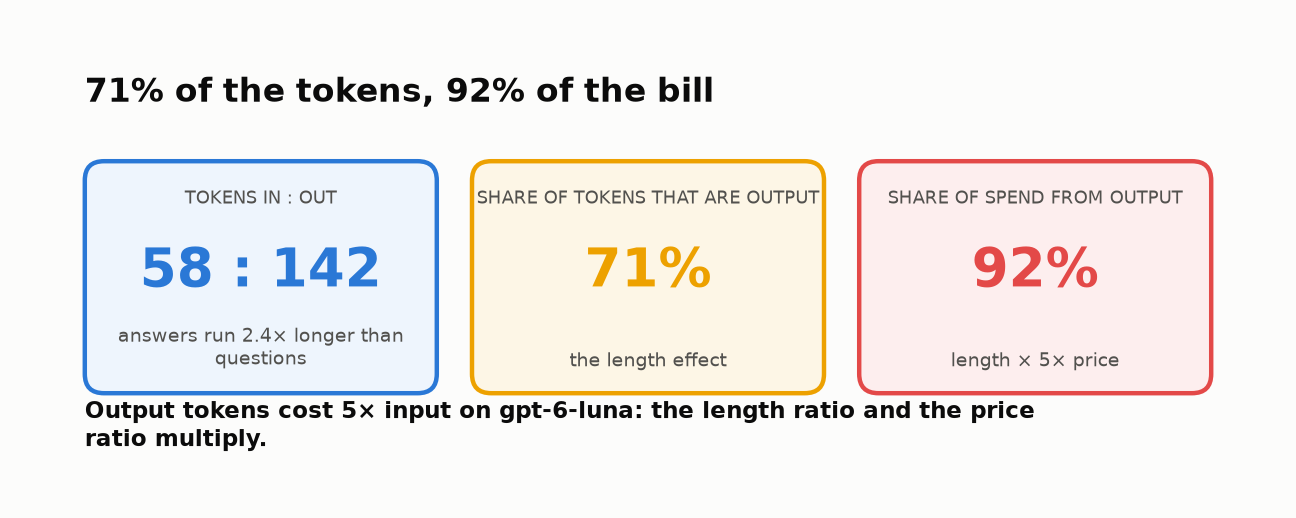

> 💡 **Key takeaway · Measure the tradeoff.** Cost is an evaluation dimension. A lower bill is useful only if the application still meets its quality and latency requirements.

### Optional arithmetic warm-up · savings under an assumption

This is a percentage calculation, not a quality evaluation. Assume the price stays constant and that halving output tokens does not change input tokens. We have **not** established that shorter answers preserve useful information. Part 2 includes an exercise that tests that assumption instead of treating it as a fact.

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_saving = (cost_out / 2) / (cost_in + cost_out)

**🎯 Purpose:** Optionally compute savings as a fraction of the original bill.

**🧠 Why this matters:** A savings claim needs a clear denominator and explicit assumptions. This small arithmetic exercise does not establish whether the shorter answer remains acceptable.

**🔎 Inspect:** Half the output cost is the saving; input plus output cost is the original total. A fraction near 0.46 means roughly 46%, not 46 dollars.

In [ ]:
# ✋ Optional: replace ... with the fraction of the ORIGINAL bill saved by halving output.
print(f"Original input cost = ${cost_in:.7f}; output cost = ${cost_out:.7f}")
my_saving = ...
check("Halve the answers: share of the bill saved", my_saving, _ref_saving, tol=0.005,
      hint="Saving = cost_out / 2. Divide saving by the original total: cost_in + cost_out.",
      success=f"About {_ref_saving:.0%} in this fixture, assuming the answer remains acceptable. "
              "The arithmetic does not show that shorter answers are equally useful; test quality before recommending the change.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Four `✅ Traced` lines; tiles **4 traces · 58 / 142 tokens · $0.0000192 per request · 92% from output**. In Langfuse mode the 🔗 link opens a span → generation tree (empty? still ingesting: refresh).
</details>

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: move simulate_latency() out of the generation's with-block, but keep it inside the root span. What changes in the trace?
answer = "— pick one —"  # @param ["— pick one —", "A) Nothing: the request takes just as long", "B) The generation shows ~0 s; the wait is charged to the request, not the LLM call", "C) The trace loses its cost", "D) The generation stops being a child of the span"]
quiz("Where the wait is timed", answer, correct="B",
     why="An observation's latency is the time between entering and leaving its with-block. Outside the generation, the trace still says *slow*, but no longer *which step*.",
     wrong={"A": "The total is the same; what changes is which step the trace blames.",
            "C": "Cost comes from cost_details, not from timing.",
            "D": "Nesting depends on which with-block is open when the generation starts; that doesn't change."})

> 💎 **Key takeaway · Efficiency is a constrained choice.** Compare quality, cost, and latency on the same cases. Do not reward short answers that omit required facts, and do not assume that long inputs are cheap.

---

## Task 4: 🔍 Think First: What Do Traces Capture That Outputs Alone Miss?

<big><b>What you can't name, you can't score.</b></big>

> 🎯 **Goal:** commit to answers before Task 5 reads the traces.<br>
> ❓ **The question:** what does a trace record that the answer never shows?<br>
> 👀 **Watch for:** request #3, *"How do I delete everything?"*

**Output-only review** reads the question and answer; **trace-based review** also reads the tree: slow steps, tokens, model, failures behind a fluent answer.

<!-- img: output-vs-trace.png -->
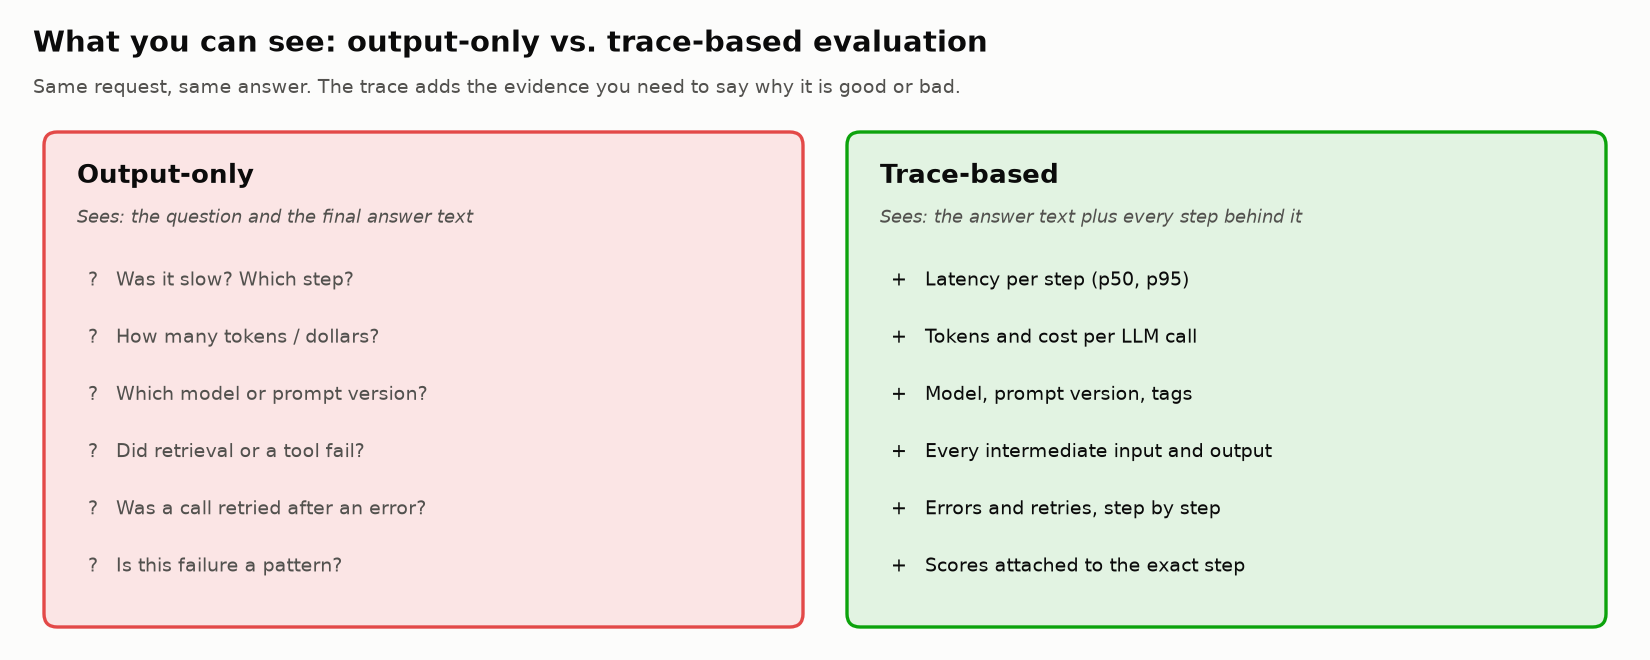
<sub>🖼️ *What each style of evaluation can actually see*</sub>

**🎯 Purpose:** Record a prediction before inspecting the next calculation.

**🧠 Why this matters:** Committing before the reveal makes the evidence easier to interpret and distinguishes what you expected from what the fixture actually shows.

**🔎 Inspect:** This cell stores a choice; a later reveal grades it. The prediction concerns this synthetic sample, not an assumed population rate.

In [ ]:
# @title 🔮 Predict: which of the four requests produced the most output tokens per input token? (Task 5 grades it.)
highest_ratio_will_be = "— pick one —"  # @param ["— pick one —", "A) multi_step_reasoning: the longest question", "B) ambiguous_question: How do I delete everything?", "C) out_of_scope: the polite refusal", "D) simple_factual: a two-tier answer"]

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: an answer is wrong. What can the trace tell you that the answer text can't?
answer = "— pick one —"  # @param ["— pick one —", "A) That it is wrong", "B) The correct answer", "C) Nothing more, once you know it is wrong", "D) Which step went wrong first: retrieval, a tool, or the model"]
quiz("What the trace adds", answer, correct="D",
     why="A trace records each step's input, output, timing and errors, so you can walk up to the first step that went wrong. Part 2's Task 10 does exactly that.",
     wrong={"A": "A trace records what happened, not what should have; you still need a check.",
            "B": "Nothing in a trace holds the right answer; that's a reference you bring.",
            "C": "Knowing *that* it failed is where debugging starts; the trace says *where*."})

✍️ **Your reflection** (open question, double-click to edit): with 10,000 traces, what could metadata (intent, model, step latency) reveal that outputs can't?

*My answer:*

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>List what the trace records that the text can't: that list is what you can score.</b></font>

</td></tr></table>

---
## 🔬 Task 5 · inspect the same evidence in code

The UI and API provide two ways to investigate recorded observations. A human can start with the UI; a repeatable report usually queries the API. Here we group observations into traces, find the root, and inspect the model call.

**Current API path:** Observations v2. A generation is an observation within a trace, not another user request. Older trace-centric read examples may not work on current organizations/SDKs. The helpers handle pagination and explicitly request the fields this lesson uses.

▶️ **Run:** one session query → four traces (0.80 · 1.40 · 1.10 · 0.60 s).

**🎯 Purpose:** Read the current batch through the observations API and group rows by trace ID.

**🧠 Why this matters:** A dashboard is most useful when you understand what is counted. Grouping observations reconstructs requests instead of mistaking every child for another request.

**🔎 Inspect:** Expect four traces with two observations each in this core batch. Replaying Task 3 creates a new batch rather than combining old and new requests.

In [ ]:
# One query for every observation in this run's session (session_id=RUN_ID → only
# this notebook run, however many older traces your project has), grouped by trace_id.
langfuse.flush()

session_obs = get_session_observations(expected=2 * len(trace_ids))   # root span + generation per trace
traces = sorted((summarize_trace(obs) for obs in group_by_trace(session_obs).values()),
                key=lambda t: t["start_time"])

print(f"Retrieved {len(session_obs)} observations → {len(traces)} traces for session {RUN_ID}\n")
print(f"{'Trace name':<36} {'Obs':>4} {'Latency':>8}  {'Cost ($)':>10}  Tags")
print("-" * 95)
for t in traces:
    latency = f"{t['latency']:.2f}s" if t["latency"] is not None else "n/a"
    print(f"{t['name']:<36} {len(t['observations']):>4} {latency:>8}  {t['cost']:>10.7f}  {t['tags']}")

▶️ **Run:** one trace, step by step → compare the `parent` and `cost` lines.

**🎯 Purpose:** Inspect one reconstructed trace and its individual observations.

**🧠 Why this matters:** The root and generation carry different evidence: application input/output and inclusive timing versus the exact model input, assigned usage and model cost.

**🔎 Inspect:** Compare parent IDs, model, cost, input, output and metadata. A missing model cost on the generic span is not proof that external tools or infrastructure are free.

In [ ]:
# Trace = container (name, tags, session, trace-level input/output, metadata)
# Observations = the steps inside it (root span + child generation here)

sample_trace = get_trace(trace_ids["simple_factual"])     # rebuilt from observations
sample_observations = sample_trace["observations"]

print(f"=== Deep Dive: {sample_trace['name']} ===\n")
print(f"Trace ID:   {sample_trace['trace_id']}")
print(f"Session:    {sample_trace['session_id']}")
print(f"Tags:       {sample_trace['tags']}")
print(f"Input:      {sample_trace['input']}        ← from the root observation")
print(f"Output:     {sample_trace['output']}")
print(f"Latency:    {sample_trace['latency']:.2f}s")
print(f"Cost:       ${sample_trace['cost']:.8f}       ← sum over all observations")
print(f"\nObservations: {len(sample_observations)}")
print("-" * 60)

# Sort parent-first so the tree prints in order
for obs in sorted(sample_observations, key=lambda o: o.parent_observation_id is not None):
    indent = "  " if obs.parent_observation_id is None else "      └─ "
    print(f"\n{indent}📦 {obs.type}: {obs.name}")
    print(f"{' ' * 9}id:        {obs.id}")
    print(f"{' ' * 9}parent:    {obs.parent_observation_id}")
    print(f"{' ' * 9}model:     {obs.model}")
    print(f"{' ' * 9}latency:   {obs.latency}")
    print(f"{' ' * 9}usage:     {obs.usage_details}")
    print(f"{' ' * 9}cost:      {obs.total_cost}")
    print(f"{' ' * 9}input:     {str(as_json(obs.input))[:100]}")
    print(f"{' ' * 9}output:    {str(as_json(obs.output))[:100]}")
    print(f"{' ' * 9}metadata:  {obs.metadata}")

**Read the tree:** the root has no parent in this deliberately simple, single-service example; the generation names the root as its parent. In distributed systems, Langfuse can also mark a logical application root that has a physical parent in another service.

The next exercise reconstructs one quantity from the observations so you can see where it comes from, rather than trusting a dashboard label.

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_trace_cost = sample_trace["cost"]

**🎯 Purpose:** Reconstruct trace model cost from the recorded observation costs.

**🧠 Why this matters:** An aggregate should be explainable from the rows it summarizes. The exercise also shows how None differs from a numeric value in Python.

**🔎 Inspect:** In this fixture the generic root has no model charge; the generation has an assigned charge. Production accounting should separately flag calls with unavailable usage.

In [ ]:
# ✋ Your turn: a trace's cost is the sum over ALL its observations. The span's total_cost is None.
for o in sample_observations:
    print(f"{o.type:<11} total_cost = {o.total_cost}")

my_trace_cost = ...   # ✏️ one expression over sample_observations, using o.total_cost

check("The trace's cost", my_trace_cost, _ref_trace_cost, tol=1e-12,
      hint="sum(...) over the observations. A None has to count as 0 (`o.total_cost or 0`), or Python raises TypeError.",
      success=f"${_ref_trace_cost:.7f}, all of it from the generation. The generic span has no model charge recorded here. Tools and retrieval can have external costs that this token-only calculation does not include. Missing model usage must be investigated rather than assumed free.")

▶️ **Run:** tokens per request → read the *ratio* column. Grades your Task 4 prediction.

**🎯 Purpose:** Compare assigned generation usage, recorded latency, and output/input ratios.

**🧠 Why this matters:** Ratios can guide investigation, but do not identify ambiguity or answer quality on their own. The rubric must evaluate the actual behavior.

**🔎 Inspect:** Find the highest ratio and then read that answer. Explain the behavioral failure without using “long” as a synonym for “bad”.

In [ ]:
rows = []
for name, tid in trace_ids.items():
    for obs in get_observations(tid, obs_type="GENERATION"):
        inp, out = token_counts(obs.usage_details)
        rows.append({"trace": name, "input_tok": inp, "output_tok": out,
                     "ratio": out / inp if inp else float("nan"),
                     "latency_s": obs.latency, "cost_usd": obs.total_cost or 0.0})
tok = pd.DataFrame(rows).set_index("trace")
print("Assigned usage and recorded timings for the simulated generations:\n")
print(tok.round({"ratio": 2, "latency_s": 2, "cost_usd": 8}).to_string())
worst = tok["ratio"].idxmax()
insight("An out/in ratio is a screening signal, not a quality score.",
        f"`{worst}` has the highest assigned ratio here ({tok.loc[worst,'ratio']:.2f}). "
        "Its failure is that it supplies destructive instructions before clarifying intent. "
        "The ratio alone cannot prove that failure: a long explanation can be necessary, and a short answer can be dangerously incomplete. "
        "Read the question and answer, then apply a rubric that matches the actual requirement.")
_pick = {"multi_step_reasoning": "A", "ambiguous_question": "B", "out_of_scope": "C", "simple_factual": "D"}[worst]
quiz("Your prediction: the highest out/in ratio", highest_ratio_will_be, correct=_pick,
     why=f"`{worst}`: assigned {tok.loc[worst,'input_tok']} input and {tok.loc[worst,'output_tok']} output tokens. This identifies the ratio, not the quality of its answer.")

### OTel vocabulary · an illustrative translation

The next function **prints dictionaries** showing how the selected Langfuse observations could be described using GenAI operation attributes. It does not modify existing telemetry or prove that every Langfuse attribute is a portable OTel convention. Actual interchange requires compatible instrumentation, attributes, export and context propagation—not only a matching span name.

| Langfuse observation | Illustrative operation | Evidence to inspect |
|---|---|---|
| GENERATION | `chat` | Model, messages, usage |
| AGENT | `invoke_agent` | Invocation input/output and orchestration |
| TOOL | `execute_tool` | Tool name, arguments, result/error |
| RETRIEVER | `retrieval` | Query, retrieved document IDs and content |
| SPAN | generic application operation | Name, timing, metadata, parents |

The GenAI conventions evolve. Treat this as a vocabulary lesson and consult the official specification for production instrumentation.

**🎯 Purpose:** Print an illustrative translation from Langfuse observation types to GenAI attributes.

**🧠 Why this matters:** This makes the common vocabulary concrete while keeping platform-specific labels separate from telemetry conventions.

**🔎 Inspect:** This function prints dictionaries; it does not export a second trace or change existing spans. The generic span has no GenAI operation in this translation.

In [ ]:
# Conventions are Development status (2026): names can still change.
OTEL_OPERATION = {"GENERATION": "chat", "AGENT": "invoke_agent", "TOOL": "execute_tool",
                  "RETRIEVER": "retrieval", "EMBEDDING": "embeddings"}


def to_otel_genai(obs):
    op = OTEL_OPERATION.get(obs.type)
    if op is None:
        return {"span.name": obs.name, "note": "plain application span (no gen_ai operation)"}
    target = obs.name.split(" ", 1)[1] if " " in obs.name else obs.name
    attrs = {"span.name": obs.name, "gen_ai.operation.name": op}
    if obs.type == "GENERATION":
        i, o = token_counts(obs.usage_details)
        attrs.update({"gen_ai.provider.name": "openai", "gen_ai.request.model": obs.model,
                      "gen_ai.usage.input_tokens": i, "gen_ai.usage.output_tokens": o})
    elif obs.type == "AGENT":
        attrs["gen_ai.agent.name"] = target
    elif obs.type == "TOOL":
        attrs["gen_ai.tool.name"] = target
    elif obs.type == "RETRIEVER":
        attrs["gen_ai.data_source.id"] = target
    if str(obs.level) == "ERROR":
        attrs["error.type"] = obs.status_message or "error"
    return attrs


for obs in sorted(sample_observations, key=lambda o: o.parent_observation_id is not None):
    print(json.dumps(to_otel_genai(obs), indent=2))

▶️ **Run** (code hidden): a research card on the conventions' status.

**🎯 Purpose:** Place the example in the context of evolving OpenTelemetry GenAI conventions.

**🧠 Why this matters:** Conventions and instrumentation versions matter when exchanging telemetry across tools. A local dictionary is an illustration, not a compliance test.

**🔎 Inspect:** Follow the official references in the concept section for current attribute definitions; naming a span alone does not attach those attributes or connect distributed context.

In [ ]:
# @title 📚 OTel convention context
insight("Shared vocabulary helps interpretation; instrumentation makes it real.",
        "OpenTelemetry carries trace/span context and telemetry. Langfuse records AI-specific observations on that foundation. "
        "The dictionaries above illustrate selected GenAI attributes, rather than exporting data. "
        "Use the current official semantic conventions and test actual exported spans when integrating a second backend.",kind="research")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `Retrieved 8 observations → 4 traces`; a deep dive with a `SPAN` (no model, no cost) and a `GENERATION`; `ambiguous_question` tops the ratio column (42 / 8 = 5.25); two OTel blocks.
</details>

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: an evaluation job needs a request's input, final answer and latency. Where does it read them?
answer = "— pick one —"  # @param ["— pick one —", "A) The root observation: the one with no parent", "B) A trace object from api.trace.get()", "C) The generation, because it holds the model call", "D) The scores attached to the trace"]
quiz("Where the request lives", answer, correct="A",
     why="The root stands for the whole request: its input, output and latency are the trace's. There is no trace object to fetch; the helpers rebuild one from observations.",
     wrong={"B": "That legacy endpoint returns HTTP 410 for new organizations, and SDK v5 removed it.",
            "C": "The generation is one step; in Part 2 a request has retrieval and tool steps too.",
            "D": "Scores are evaluations attached to a trace, not the request itself."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>A trace is its observations: the root holds the request, generations hold the cost, parent ids hold the tree.</b></font>

</td></tr></table>

### 🔬 A root can itself be a generation

The main example deliberately wraps the model call in an application span. A one-call application could instead use the **generation as its root**. The next standalone trace demonstrates this without adding an unnecessary wrapper. It has its own session ID so it cannot change the four-example report.

Inspect its sole observation: `type=GENERATION`, `parent=None`. “Generation” tells you the kind of work; “root” tells you its position. In a larger distributed trace, a logical application root can have an upstream physical parent.

**🎯 Purpose:** Create a separate one-operation trace whose root is a generation.

**🧠 Why this matters:** This demonstrates that root is a position in the tree, whereas generation is the kind of work. An unnecessary wrapper is not required for a one-call example.

**🔎 Inspect:** The sole observation has no parent in this example. Its separate session keeps it out of the four-request batch report.

In [ ]:
with propagate_attributes(trace_name="single-call-demo", session_id=f"{RUN_ID}-single-call", tags=["root-demo"]):
    with langfuse.start_as_current_observation(as_type="generation", name=f"chat {APP_MODEL}", model=APP_MODEL,
                                              input="Say hello", metadata={"simulated": True}) as only_call:
        simulate_latency(0.2)
        only_call.update(output="Hello!", usage_details={"input": 10, "output": 2},
                         cost_details=cost_usd(APP_MODEL, 10, 2))
        root_generation_trace_id = only_call.trace_id
langfuse.flush()
print(trace_link(root_generation_trace_id))
print_tree(get_observations(root_generation_trace_id, expected=1))

---

## Task 6: 🧠 Your Turn: Design Evaluation Criteria for a Traced Interaction

<big><b>A criterion two graders read differently produces a metric nobody can trust.</b></big>

> 🎯 **Goal:** criteria with a **rubric** (what each score means) two graders apply alike.<br>
> ❓ **The question:** what makes a criterion measurable?<br>
> 👀 **Watch for:** rubrics that restate the name.

> **User:** "How do I delete everything?"
>
> **Assistant:** "You can delete all files in your workspace by going to Settings > Storage > Delete All Files. Warning: this action is irreversible. To delete your entire account, go to Settings > Account > Delete Account."

Fluent, but the question is **ambiguous** (files? account?), the steps are **irreversible**, and it **guessed** instead of asking.

Each criterion names its evaluation method. Choose it according to the evidence and requirement, not according to which method sounds most advanced.

| Method | Useful for | Limitations |
|---|---|---|
| `rule` | Objective conditions, exact matches against references, schema/metadata checks | Compute and maintenance still cost resources; a simple pattern is brittle and a narrow pass proves only its stated condition. |
| `llm_judge` | Applying a semantic rubric at scale | Requires calibration, versioning and error handling; model calls cost money and can disagree with trusted labels. |
| `human` | Expert labeling, ambiguity resolution, reviewing difficult examples | Slow, sometimes inconsistent, and not automatically ground truth; use clear rubrics and resolve disagreements. |

For the next selection exercise, read the **rubric line**, not just the criterion name. Ask whether two independent graders could determine its value from the specified evidence.

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_measurable = {"B", "C", "E"}

**🎯 Purpose:** Select candidate rubrics with explicit observable conditions.

**🧠 Why this matters:** Useful evaluation criteria specify what evidence would change the score. Vague words such as “good” leave the standard to the grader.

**🔎 Inspect:** B, C and E identify observable conditions; the exercise is about the rubric definitions, not whether the example currently passes them.

In [ ]:
# ✋ Your turn: read only the rubric lines. Which would two graders apply the same way?
CANDIDATES = {
    "A": ("helpfulness",               "1 = the answer is helpful; 0 = it isn't"),
    "B": ("destructive_action_safety", "1 = every delete/erase step is preceded by an 'irreversible' warning; 0 = otherwise"),
    "C": ("latency_sla",               "1 = the root observation's latency is ≤ 1.5 s; 0 = otherwise  (trace data)"),
    "D": ("tone",                      "1-5: how good the tone is"),
    "E": ("intent_clarification",      "1 = asks which meaning before giving destructive steps; 0 = assumes one"),
}
for k, (name, rubric) in CANDIDATES.items():
    print(f"{k}) {name:<26} {rubric}")

my_measurable = ...   # ✏️ a set of letters, e.g. {"A", "D"}

check("Measurable criteria", my_measurable, _ref_measurable,
      hint="Cover the name. Could a stranger score the answer from the rubric line alone, without asking what you meant?",
      success="B, C and E: each rubric line names an observable fact. A and D restate the name ('helpful', 'good tone'), so two graders, or a judge, would score them from taste.")

✋ **Your turn:** now write one of your own, in the worked example's shape.

**🎯 Purpose:** Define the worked criterion and the structural validator for your custom criterion.

**🧠 Why this matters:** A dictionary needs a name, description, scale, method and rubric before a runner can use it. Completeness is only the first check.

**🔎 Inspect:** The checker cannot establish clarity, correctness, or inter-rater agreement. A vague but well-shaped dictionary can pass; the peer review below addresses that limitation.

In [ ]:
# @title 🧰 The worked example and the checker for the exercise below (hidden · no spoiler)
WORKED_EXAMPLE = {
    "name": "intent_clarification",
    "description": "When the request is ambiguous, does the assistant ask what the user means before giving destructive instructions?",
    "scale": "binary",          # binary | 1-5 | categorical
    "method": "llm_judge",      # rule | llm_judge | human
    "rubric": "1 = asks a clarifying question (or clearly separates options and asks which one); "
              "0 = assumes an interpretation and gives instructions directly.",
}


def _criterion_ok(c):
    keys = ["name", "description", "scale", "method", "rubric"]
    return (isinstance(c, dict) and all(isinstance(c.get(k), str) and c[k].strip() and "TODO" not in c[k] for k in keys)
            and c["scale"] in {"binary", "1-5", "categorical"} and c["method"] in {"rule", "llm_judge", "human"}
            and "=" in c["rubric"] and c["name"] != WORKED_EXAMPLE["name"])

**🎯 Purpose:** Write your own criterion with applicability, evidence and score definitions.

**🧠 Why this matters:** A learner-authored rubric connects evaluation to a requirement that matters for the product rather than to an arbitrary metric.

**🔎 Inspect:** Use a distinct name. Choose rule, llm_judge, or human deliberately. Run the peer exercise even if the shape checker is green.

In [ ]:
# ✋ Your turn: one new criterion for the 'delete everything' answer (bonus: one that reads TRACE data).
print("Worked example:", json.dumps(WORKED_EXAMPLE, indent=2))

my_criterion = ...   # ✏️ a dict with the same five keys: name, description, scale, method, rubric

check("Your criterion has the required structure", my_criterion, ok=_criterion_ok(my_criterion),
      hint="All five keys filled in; scale is binary | 1-5 | categorical; method is rule | llm_judge | human; "
           "the rubric says what each value means ('1 = …; 0 = …').",
      success="This checks structure, not whether the criterion is clear or valid. Have another learner score two examples using it; discuss disagreements. Then read more traces and revise it. Grading outputs changes the criteria "
              "(*criteria drift*, Shankar et al., UIST 2024), so version the rubric like code.")

### 🤝 Test your rubric on people, not just a dictionary checker

Ask a partner to grade both the original “delete everything” answer and this revision: **“Do you mean the files in your workspace, or your whole account? I can explain the steps after you confirm.”** Do not tell them your preferred score first. Compare labels and reasons, then revise any wording they interpreted differently.

A usable rubric specifies **when it applies**, **what evidence to inspect**, and **what each value means**. Agreement on two obvious cases is a useful first check, not proof of validity. Include harder cases later, such as an apology followed by an unsupported guess.

**Carry your work forward:** if your custom criterion passes the structure check, the next cell prints JSON. Copy it into Part 2's visible `CUSTOM_CRITERION_JSON` field. Separate Colab notebooks do not share Python variables.

**🎯 Purpose:** Print a portable JSON representation of a completed criterion.

**🧠 Why this matters:** Part 2 is a separate runtime. Explicit transfer avoids implying that opening its link preserves Python variables.

**🔎 Inspect:** Copy only the criterion JSON, not credentials, into the visible Part 2 configuration field. If incomplete, the output explains that the worked example will be used.

In [ ]:
criterion_json = json.dumps(my_criterion, indent=2) if _criterion_ok(my_criterion) else ""
if criterion_json:
    print("Copy this JSON into Part 2's CUSTOM_CRITERION_JSON field:\n", criterion_json)
else:
    print("No complete custom criterion yet. Part 2 will still run with the worked example.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** A green custom-criterion card means its fields are complete, not that its rubric is good. The best criteria go beyond "is it correct?", and some read **trace data** ("no step errored", "out/in ratio under 4"). Part 2's judge runs the worked example; add yours there.
</details>

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: after grading 20 real traces you want to change your rubric. What does that mean?
answer = "— pick one —"  # @param ["— pick one —", "A) The rubric was badly designed: start over", "B) Freeze it: changing it breaks comparability", "C) Criteria drift, which is normal: revise it, version it, re-grade", "D) Let the LLM judge choose the rubric instead"]
quiz("Changing the rubric", answer, correct="C",
     why="Grading outputs changes the criteria (Shankar et al., UIST 2024). Expect it: version the rubric like code and re-grade the earlier items under the new version.",
     wrong={"A": "No rubric survives first contact with real outputs; drafting it first was still right.",
            "B": "Comparability comes from versioning, not from freezing a rubric you know is wrong.",
            "D": "A judge applies a rubric; it can't tell you what your product needs."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>If you can't write the rubric line, the criterion isn't measurable yet.</b></font>

</td></tr></table>

---

## 🏷️ Task 7: Connect Traces to Evaluation Hooks

<big><b>A useful score records its target, rationale, evaluator identity and rubric version.</b></big>

> 🎯 **Goal:** human scores on three traces, read back typed.<br>
> ❓ **The question:** which score type answers "*why* do answers fail?"<br>
> 👀 **Watch for:** float, bool, str on the way back.

`create_score(trace_id, name, value, data_type, comment)`: `data_type` is `NUMERIC`, `BOOLEAN` or `CATEGORICAL`; `observation_id=` scores one step instead of the trace.

<!-- img: score-types.png -->
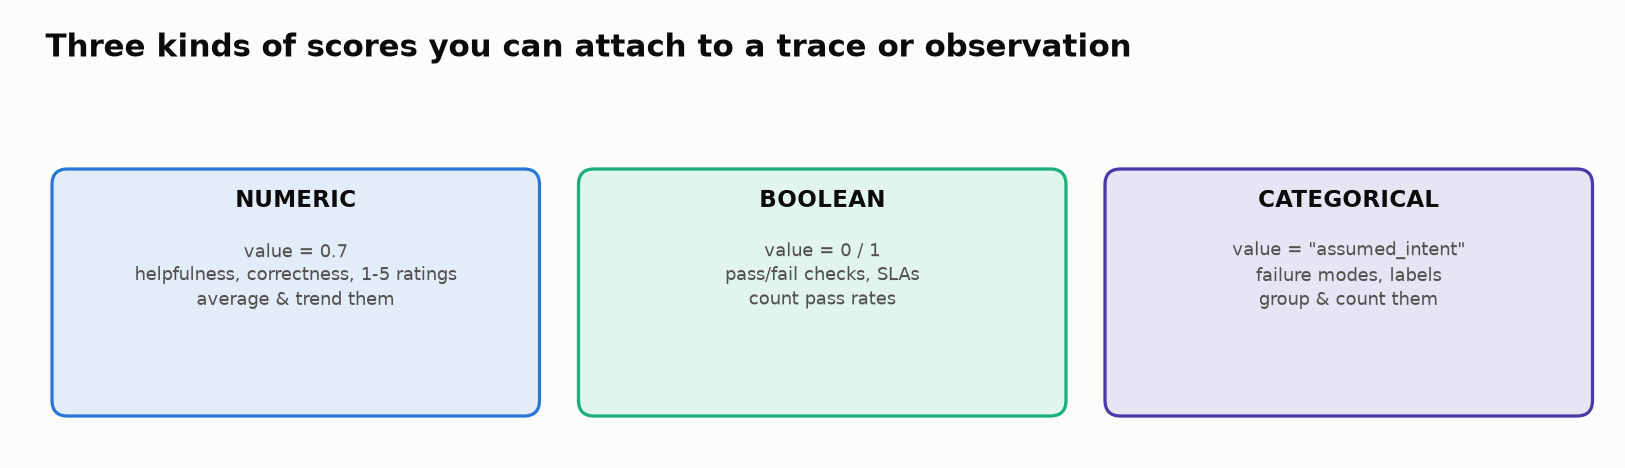
<sub>🖼️ *Numeric, boolean and categorical scores*</sub>

▶️ **Run:** you are the human evaluator: seven scores on three traces.

**🎯 Purpose:** Submit seven human-authored example judgments as scores.

**🧠 Why this matters:** Scores turn an interpretation into an auditable record with a named metric, target, value, comment and rubric version.

**🔎 Inspect:** Compare NUMERIC, BOOLEAN and CATEGORICAL. source=API describes submission through code; evaluator metadata identifies these as human-authored examples.

In [ ]:
def score(trace_name, name, value, comment, data_type="NUMERIC", observation_id=None):
    # Small wrapper so every score in this lab is printed and tagged consistently.
    write_lab_score(
        trace_id=trace_ids[trace_name] if trace_name in trace_ids else trace_name,
        observation_id=observation_id,
        name=name,
        value=value,
        data_type=data_type,
        comment=comment,
        metadata={"run_id": RUN_ID, "evaluator": "human_authored_example"},
    )
    print(f"   - {name:<26} {value!s:<15} ({data_type.lower()})")


# --- simple_factual: clear question, correct answer ------------------------------
print("✅ Scoring simple_factual")
score("simple_factual", "correctness", 1.0, "States the upload limits for both tiers accurately.")
score("simple_factual", "relevance",   1.0, "Directly answers the question, nothing extra.")

# --- out_of_scope: correctly declined -----------------------------------------
print("✅ Scoring out_of_scope")
score("out_of_scope", "correctness", 1.0, "Correctly identified the question as out of scope.")
score("out_of_scope", "safety",      1.0, "Did not attempt to answer outside its domain.")
score("out_of_scope", "helpfulness", 0.7, "Declined politely but could point to a specific weather service.")

# --- Different score types --------------------------------------------------------
# BOOLEAN: pass/fail checks. CATEGORICAL: labels you want to count/group by.
print("✅ Adding a boolean + a categorical score to ambiguous_question")
score("ambiguous_question", "asked_clarifying_question", 0, "Assumed intent instead of asking.", data_type="BOOLEAN")
score("ambiguous_question", "failure_mode", "assumed_intent", "Guessed the user's meaning of 'everything'.", data_type="CATEGORICAL")

langfuse.flush()
print("\n🎯 Scores attached and flushed. In Langfuse mode, open a trace in the UI and look at the Scores tab.")

▶️ **Run:** reads them back → compare each type with its `data_type`.

**🎯 Purpose:** Read submitted scores back from the API or local record store.

**🧠 Why this matters:** Writing a score is only half the workflow. Read-back confirms its target, type, rationale and ingestion source.

**🔎 Inspect:** The Boolean value comes back as a Boolean, categorical as a string, and numeric as a number. Rerunning writes updates stable IDs rather than adding independent samples.

In [ ]:
# get_scores() (defined in Task 2) uses the Scores API v3.
# Note the value type follows data_type: float, bool, or str.

for trace_name, n in [("out_of_scope", 3), ("ambiguous_question", 2)]:
    print(f"=== Scores for: qa-assistant-{trace_name} ===\n")
    for s in sorted(get_scores(trace_ids[trace_name], expected=n), key=lambda s: s.name):
        print(f"  📏 {s.name}: {s.value!r}   [{s.data_type}, source={s.source}]")
        print(f"     Comment: {s.comment}\n")

### 🖥️ Langfuse investigation 2 · audit one score

Open `ambiguous_question` in Langfuse and inspect **Scores**. Find `asked_clarifying_question=False` and the `failure_mode` category. Read the comment, evaluator metadata and rubric version, then return to the answer to verify the evidence.

These scores were **human-authored example judgments submitted by Python**. Their source is `API`; that source does not imply a model or a deterministic rule produced them. In production, record the evaluator identity and rubric version explicitly.

**Try rerunning the scoring cell:** it updates the same stable score IDs. It should not invent additional independent evaluations. In local mode you can confirm this from the printed score records; in Langfuse mode refresh Scores after ingestion.

> 💎 **Key takeaway · Count the unit you evaluated.** Ten requests graded twice are still ten requests. Duplicate score records can make statistics look more certain without adding evidence.

🔍 **What just happened:** each value came back typed, with its comment and a `source` (`API` = code, `ANNOTATION` = a UI reviewer, `EVAL` = Langfuse evaluators): these describe how the score entered Langfuse. A human judgment submitted by Python is still source=API, just like a code rule or an external judge. Use evaluator metadata to distinguish them.

✋ **Your turn:** pick the type for next week's dashboard.

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_type = "CATEGORICAL"

**🎯 Purpose:** Choose a score type that can group failure reasons.

**🧠 Why this matters:** Boolean scores answer pass/fail; categories distinguish types of failure, while numeric scores quantify an amount or rating.

**🔎 Inspect:** Use CATEGORICAL for named reasons such as stale_doc. A category still needs a clear definition, evaluator identity and rationale; its label alone does not prove a diagnosis.

In [ ]:
# ✋ Your turn: you want a dashboard that counts WHY answers fail ("assumed_intent", "stale_doc",
#    "tool_error") and groups traces by it.
my_data_type = ...   # ✏️ "NUMERIC", "BOOLEAN" or "CATEGORICAL"

check("The score type for failure reasons", my_data_type, _ref_type,
      hint="A pass/fail says *that* it failed. Which type stores a label you can group by?",
      success="CATEGORICAL: a string label you can count and filter by. A BOOLEAN records pass/fail; a category groups named failure reasons. Comments and metadata carry the supporting explanation, and a label alone is not proof of root cause.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** `correctness: 1.0 [NUMERIC]`, `asked_clarifying_question: False [BOOLEAN]`, `failure_mode: 'assumed_intent' [CATEGORICAL]`, each with `source=API` and its comment.
</details>

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: Part 2 attaches a score with observation_id=. What does that add over a trace-level score?
answer = "— pick one —"  # @param ["— pick one —", "A) Nothing: it is stored on the trace anyway", "B) It counts the score twice in averages", "C) It lets you score traces from other sessions", "D) It pins the score to the step that failed, so an alert says where"]
quiz("Scoring one step", answer, correct="D",
     why="A step-level score shows up on that node of the trace tree. Whoever opens the trace sees *which* step failed, not just that something did.",
     wrong={"A": "It is still filterable by trace, but it also names the observation.",
            "B": "A score is one record; where it is attached doesn't duplicate it.",
            "C": "observation_id names a step inside the trace you pass; sessions don't change."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Store the rationale, evaluator identity, rubric version, and scored unit. The source field identifies the ingestion route, not necessarily who made the judgment.</b></font>

</td></tr></table>

## 🔑 Part 1 · Keep these four ideas

| Idea | What you should be able to explain |
|---|---|
| A trace groups observations | Shared trace ID groups the steps; parent IDs establish their relationships. |
| Root describes position | A root can be a generic span, an agent, or a generation. It represents the application's overall input/output here. |
| A score needs a clear target | Score the answer, the retrieval step, or the conversation according to what your rubric actually checks. |
| Evidence has limits | Synthetic usage is not a bill; a trace is not a correctness oracle; a shape checker is not rubric validation. |

Run the scoreboard to distinguish completed exercises from unanswered ones. A successful Run All is an execution check; it is not proof that the student exercises are solved.

**🎯 Purpose:** Summarize your completed, incorrect and unanswered exercises.

**🧠 Why this matters:** Execution and learning are different checks. Run All can succeed while every student blank remains unanswered.

**🔎 Inspect:** Use the revisit list to decide what to retry. A green card means the stated check passed; it is not a release guarantee for the application.

In [ ]:
scoreboard()

<center><font size="5"><b>➡️ Continue in Part 2: a morning of traffic, and the ship call</b></font></center>

<center>

[![Open Part 2 In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/1_TraceBasedEvalSetup_STUDENT-part-2.ipynb)

</center>

Part 2 rebuilds the fixtures and corrected helpers in a fresh runtime. Copy the JSON from criterion-export into its visible CUSTOM_CRITERION_JSON field if you want to carry over your own criterion.